In [2]:
!pip install pandas pyarrow fastparquet matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 88.1 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 86.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 80.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 65.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 75.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 64.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [fastparquet] [fastparquet]


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


DATA_DIR = "/zfs/ai4good/datasets/forest_disturbance"


samples_df = pd.read_parquet(os.path.join(DATA_DIR, "samples.parquet"))
labels_df = pd.read_parquet(os.path.join(DATA_DIR, "labels.parquet"))
splits_df = pd.read_parquet(os.path.join(DATA_DIR, "splits.parquet"))

print(f"Samples shape: {samples_df.shape}")
print(f"Labels shape: {labels_df.shape}")
print(f"Splits shape: {splits_df.shape}")

Samples shape: (3777, 16)
Labels shape: (7851, 9)
Splits shape: (18885, 3)


In [4]:
import pandas as pd

print("Samples columns:", list(samples_df.columns))
print("Labels columns: ", list(labels_df.columns))
print("Splits columns: ", list(splits_df.columns))

Samples columns: ['sample_id', 'original_sample_id', 'lon', 'lat', 'geometry', 'mgrs_tile', 'dataset', 'source', 'source_description', 'interpreter', 'cluster_id', 'cluster_description', 'comment', 'confidence', 'window_start', 'window_end']
Labels columns:  ['sample_id', 'period_idx', 'label', 'start', 'end_evidence', 'end_validity', 'is_event', 'has_overlap_with_next', 'overlap_days']
Splits columns:  ['sample_id', 'fold_id', 'split']


In [5]:
import pandas as pd

# Checkpoint 1: Label distribution and basic flags
print("=== 1. Label Value Counts ===")
print(labels_df['label'].value_counts(dropna=False))

print("\n=== 2. Event Breakdown (is_event) ===")
print(labels_df['is_event'].value_counts(dropna=False))

print("\n=== 3. Overlap Flags ===")
print(labels_df['has_overlap_with_next'].value_counts(dropna=False))

print("\n=== 4. First 5 Rows of Labels ===")
display(labels_df.head(5))

=== 1. Label Value Counts ===
label
110    3625
120    1178
211     575
243     424
222     351
121     315
242     292
212     250
231     244
123     155
221     152
122     129
220      61
213      41
232      27
230      10
245       9
200       8
241       4
240       1
Name: count, dtype: int64

=== 2. Event Breakdown (is_event) ===
is_event
False    5687
True     2164
Name: count, dtype: int64

=== 3. Overlap Flags ===
has_overlap_with_next
False    7833
True       18
Name: count, dtype: int64

=== 4. First 5 Rows of Labels ===


,sample_id,period_idx,label,start,end_evidence,end_validity,is_event,has_overlap_with_next,overlap_days
0,0,0,110,2016-11-10,2022-03-09,2022-04-08,False,False,0
1,0,1,212,2022-04-08,2022-04-08,2024-04-02,True,False,0
2,0,2,211,2024-04-02,2024-04-02,None,True,False,0
3,1,0,110,2016-11-10,2023-05-03,2023-06-22,False,False,0
4,1,1,211,2023-06-22,2023-06-22,None,True,False,0


In [6]:
print("=== 1. Unique Labels and their Counts ===")
print(labels_df['label'].value_counts(dropna=False))

print("\n=== 2. True vs False Breakdown for is_event ===")
print(labels_df['is_event'].value_counts(dropna=False))

print("\n=== 3. Missing / Null Values in Labels ===")
print(labels_df.isnull().sum())

print("\n=== 4. Check Number of Periods per Sample ===")
print(labels_df.groupby('sample_id')['period_idx'].count().value_counts())

=== 1. Unique Labels and their Counts ===
label
110    3625
120    1178
211     575
243     424
222     351
121     315
242     292
212     250
231     244
123     155
221     152
122     129
220      61
213      41
232      27
230      10
245       9
200       8
241       4
240       1
Name: count, dtype: int64

=== 2. True vs False Breakdown for is_event ===
is_event
False    5687
True     2164
Name: count, dtype: int64

=== 3. Missing / Null Values in Labels ===
sample_id                   0
period_idx                  0
label                       0
start                       0
end_evidence                0
end_validity             3777
is_event                    0
has_overlap_with_next       0
overlap_days                0
dtype: int64

=== 4. Check Number of Periods per Sample ===
period_idx
1    1864
3    1069
4     485
2     320
5      34
6       5
Name: count, dtype: int64


In [7]:
# Checkpoint 3: Event cross-tabulation and Samples inspection
print("=== 1. Cross-tab of label vs is_event ===")
display(pd.crosstab(labels_df['label'], labels_df['is_event']))

print("\n=== 2. Missing Values in Samples ===")
print(samples_df.isnull().sum())

print("\n=== 3. Unique Interpreters and Confidence in Samples ===")
if 'confidence' in samples_df.columns:
    print("Confidence counts:\n", samples_df['confidence'].value_counts(dropna=False))
if 'interpreter' in samples_df.columns:
    print("\nInterpreters count:\n", samples_df['interpreter'].nunique())

=== 1. Cross-tab of label vs is_event ===


is_event,False,True
label,,
110,3625,0
120,1178,0
121,315,0
122,129,0
123,155,0
200,0,8
211,0,575
212,0,250
213,0,41



=== 2. Missing Values in Samples ===
sample_id                0
original_sample_id       0
lon                      0
lat                      0
geometry                 0
mgrs_tile                0
dataset                  0
source                   0
source_description       0
interpreter              0
cluster_id              35
cluster_description      0
comment                137
confidence               0
window_start             0
window_end               0
dtype: int64

=== 3. Unique Interpreters and Confidence in Samples ===
Confidence counts:
 confidence
high      3182
medium     594
             1
Name: count, dtype: int64

Interpreters count:
 4


In [8]:
# Checkpoint 4: Investigating anomalies in confidence and time intervals

# 1. Inspect the 1 sample with blank/whitespace confidence
blank_conf_mask = samples_df['confidence'].str.strip() == ''
print("=== 1. Sample with blank confidence ===")
display(samples_df[blank_conf_mask][['sample_id', 'interpreter', 'confidence', 'comment', 'dataset']])

# 2. Check for temporal duration validity in labels (end before start?)
labels_temp = labels_df.copy()
labels_temp['start'] = pd.to_datetime(labels_temp['start'])
labels_temp['end_evidence'] = pd.to_datetime(labels_temp['end_evidence'])

invalid_duration = labels_temp[labels_temp['end_evidence'] < labels_temp['start']]
print(f"\n=== 2. Labels where end_evidence < start: {len(invalid_duration)} ===")
if len(invalid_duration) > 0:
    display(invalid_duration.head())

# 3. Check distribution of positive overlap_days
positive_overlaps = labels_df[labels_df['overlap_days'] > 0]
print(f"\n=== 3. Labels with overlap_days > 0: {len(positive_overlaps)} ===")
print("Summary statistics of overlap_days:")
print(positive_overlaps['overlap_days'].describe())

=== 1. Sample with blank confidence ===


,sample_id,interpreter,confidence,comment,dataset
3085,3130,,,,2



=== 2. Labels where end_evidence < start: 0 ===

=== 3. Labels with overlap_days > 0: 18 ===
Summary statistics of overlap_days:
count      18.000000
mean     1919.444444
std       595.396973
min       855.000000
25%      1451.250000
50%      2037.500000
75%      2183.750000
max      3145.000000
Name: overlap_days, dtype: float64


In [9]:
# Checkpoint 5: Deep-dive into overlapping records and Splits integrity

# 1. Inspect the sample_ids with positive overlaps
overlap_sample_ids = labels_df[labels_df['overlap_days'] > 0]['sample_id'].unique()
print(f"=== 1. Number of samples affected by overlaps: {len(overlap_sample_ids)} ===")
print("Affected sample IDs:", overlap_sample_ids[:10])

# 2. View all periods for the first 2 affected samples to see the conflicting dates
print("\n=== 2. Example timelines of affected samples ===")
sample_preview = labels_df[labels_df['sample_id'].isin(overlap_sample_ids[:2])].sort_values(by=['sample_id', 'period_idx'])
display(sample_preview[['sample_id', 'period_idx', 'label', 'start', 'end_evidence', 'end_validity', 'is_event', 'overlap_days']])

# 3. Check Splits breakdown (verifying fold distributions)
print("\n=== 3. Splits Fold Breakdown ===")
display(splits_df.groupby(['fold_id', 'split']).size().unstack(fill_value=0))

=== 1. Number of samples affected by overlaps: 18 ===
Affected sample IDs: [ 970  995 1009 1025 1094 1101 1109 1118 1127 1136]

=== 2. Example timelines of affected samples ===


,sample_id,period_idx,label,start,end_evidence,end_validity,is_event,overlap_days
2901,970,0,110,2016-02-17,2024-12-31,2021-11-25,False,1132
2902,970,1,213,2021-11-25,2021-11-25,None,True,0
2931,995,0,110,2016-02-17,2024-12-26,2017-02-14,False,2872
2932,995,1,213,2017-02-14,2017-02-14,None,True,0



=== 3. Splits Fold Breakdown ===


split,train,val
fold_id,,
0,3053,724
1,3025,752
2,3058,719
3,3039,738
4,2933,844


In [10]:
import os

# Checkpoint 6: Spatial checks & Patches inspection

# 1. Geographic spread of the dataset (lat/lon bounds)
print("=== 1. Coordinate Bounding Box ===")
print(samples_df[['lat', 'lon']].describe().T[['min', 'mean', 'max']])

# 2. Check if folds are spatially clustered (e.g., MGRS tile or lat/lon)
print("\n=== 2. MGRS Tiles count ===")
print(f"Total unique MGRS tiles: {samples_df['mgrs_tile'].nunique()}")
print("Top 5 MGRS tiles:\n", samples_df['mgrs_tile'].value_counts().head(5))

# 3. Inspect what is inside the 'patches' directory
PATCHES_DIR = "/zfs/ai4good/datasets/forest_disturbance/patches"
if os.path.exists(PATCHES_DIR):
    patch_items = os.listdir(PATCHES_DIR)
    print(f"\n=== 3. Patches Directory Contents ({len(patch_items)} items found) ===")
    print("First 10 items in patches:", patch_items[:10])
else:
    print("\n=== 3. Patches Directory: Not found at specified path ===")

=== 1. Coordinate Bounding Box ===
           min       mean        max
lat  36.461404  50.340031  69.395896
lon  -8.953415   9.781662  27.272129

=== 2. MGRS Tiles count ===
Total unique MGRS tiles: 95
Top 5 MGRS tiles:
 mgrs_tile
35VMJ    385
33UVS    345
30TXQ    254
29SPC    234
33VVJ    232
Name: count, dtype: int64

=== 3. Patches Directory Contents (3777 items found) ===
First 10 items in patches: ['1162.zarr', '3133.zarr', '602.zarr', '2369.zarr', '1006.zarr', '766.zarr', '3057.zarr', '1129.zarr', '2322.zarr', '649.zarr']


In [12]:
import os
import pandas as pd

# Checkpoint 7: Spatial CV integrity and Patch folder structure

# 1. Check if MGRS tiles leak across train and validation in fold 0
sample_splits = samples_df.merge(splits_df[splits_df['fold_id'] == 0], on='sample_id')
train_tiles = set(sample_splits[sample_splits['split'] == 'train']['mgrs_tile'])
val_tiles = set(sample_splits[sample_splits['split'] == 'val']['mgrs_tile'])
leaked_tiles = train_tiles.intersection(val_tiles)

print("=== 1. MGRS Tile Overlap in Fold 0 ===")
print(f"Train tiles: {len(train_tiles)} | Val tiles: {len(val_tiles)}")
print(f"Overlapping tiles between Train and Val: {len(leaked_tiles)}")

# 2. Inspect the raw internal structure of a .zarr folder using standard OS tools
PATCHES_DIR = "/zfs/ai4good/datasets/forest_disturbance/patches"
first_sample_id = samples_df['sample_id'].iloc[0]
sample_zarr_path = os.path.join(PATCHES_DIR, f"{first_sample_id}.zarr")

print(f"\n=== 2. Files inside {first_sample_id}.zarr ===")
if os.path.exists(sample_zarr_path):
    print(os.listdir(sample_zarr_path))
else:
    print("Path does not exist:", sample_zarr_path)

=== 1. MGRS Tile Overlap in Fold 0 ===
Train tiles: 87 | Val tiles: 58
Overlapping tiles between Train and Val: 50

=== 2. Files inside 0.zarr ===
['s2_scl', 's1', 's2_60m', 's2_20m', 's2_10m', 'zarr.json']


In [13]:
# Checkpoint 8: Cluster distribution and Annotator breakdown

# 1. Inspect the 35 samples with missing cluster_id
null_clusters = samples_df[samples_df['cluster_id'].isnull()]
print(f"=== 1. Missing cluster_id samples count: {len(null_clusters)} ===")
display(null_clusters[['sample_id', 'interpreter', 'confidence', 'cluster_description', 'mgrs_tile']].head(5))

# 2. Annotator breakdown vs Confidence
print("\n=== 2. Interpreter vs. Confidence Matrix ===")
display(pd.crosstab(samples_df['interpreter'], samples_df['confidence'], dropna=False))

# 3. Check what the dataset column contains
print("\n=== 3. Dataset column breakdown ===")
print(samples_df['dataset'].value_counts())

=== 1. Missing cluster_id samples count: 35 ===


,sample_id,interpreter,confidence,cluster_description,mgrs_tile
711,756,vij,high,Damage polygons,32UMU
714,759,vij,high,Damage polygons,32UMU
746,791,vij,high,Damage polygons,32UNC
747,792,vij,high,Damage polygons,32UNC
748,793,vij,high,Damage polygons,32UNC



=== 2. Interpreter vs. Confidence Matrix ===


confidence,,high,medium
interpreter,,,
,1,0,0
bur,0,34,36
pum,0,982,346
vij,0,2166,212



=== 3. Dataset column breakdown ===
dataset
2    2615
1     868
3     294
Name: count, dtype: int64


In [14]:
import os
import json

# Checkpoint 9: Inspect array shapes and metadata inside 0.zarr
sample_0_dir = "/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr"

print("=== 1. Root Metadata (zarr.json) ===")
root_json_path = os.path.join(sample_0_dir, "zarr.json")
if os.path.exists(root_json_path):
    with open(root_json_path, 'r') as f:
        meta = json.load(f)
        print("Root JSON keys:", list(meta.keys()))
        print(json.dumps(meta, indent=2)[:400], "...\n")

print("=== 2. Inspecting s2_10m Metadata ===")
s2_10m_json = os.path.join(sample_0_dir, "s2_10m", "zarr.json")
if os.path.exists(s2_10m_json):
    with open(s2_10m_json, 'r') as f:
        s2_meta = json.load(f)
        print("s2_10m array shape:", s2_meta.get("shape"))
        print("s2_10m data type:", s2_meta.get("data_type"))
        print("s2_10m chunk shape:", s2_meta.get("chunk_grid", {}))

=== 1. Root Metadata (zarr.json) ===
Root JSON keys: ['attributes', 'zarr_format', 'node_type']
{
  "attributes": {
    "sample_id": 0,
    "crs": "EPSG:32630",
    "patch_transform": [
      10.0,
      0.0,
      398550.0,
      0.0,
      -10.0,
      4068080.0
    ],
    "lon": -4.122119320177979,
    "lat": 36.741785367381176,
    "tile": "30SUF",
    "sample_aliases": [
      0
    ]
  },
  "zarr_format": 3,
  "node_type": "group"
} ...

=== 2. Inspecting s2_10m Metadata ===
s2_10m array shape: [528, 4, 252, 252]
s2_10m data type: uint16
s2_10m chunk shape: {'name': 'regular', 'configuration': {'chunk_shape': [64, 4, 252, 252]}}


In [15]:
import os
import pandas as pd

DATA_DIR = "/zfs/ai4good/datasets/forest_disturbance"
zarr_frames_df = pd.read_parquet(os.path.join(DATA_DIR, "zarr_frames.parquet"))

print("=== 1. zarr_frames Shape & Columns ===")
print("Shape:", zarr_frames_df.shape)
print("Columns:", list(zarr_frames_df.columns))

print("\n=== 2. Preview for sample_id = 0 ===")
sample_0_frames = zarr_frames_df[zarr_frames_df['sample_id'] == 0]
print(f"Total frames recorded for sample 0: {len(sample_0_frames)}")
display(sample_0_frames.head(5))

print("\n=== 3. Missing values in zarr_frames ===")
print(zarr_frames_df.isnull().sum())

=== 1. zarr_frames Shape & Columns ===
Shape: (5513417, 6)
Columns: ['sample_id', 'sensor', 'date', 'zarr_id', 'orbit', 'direction']

=== 2. Preview for sample_id = 0 ===
Total frames recorded for sample 0: 1198


,sample_id,sensor,date,zarr_id,orbit,direction
0,0,s1,2016-11-10,0,74.0,ASCENDING
1,0,s1,2016-11-11,1,1.0,ASCENDING
2,0,s1,2016-11-16,3,74.0,ASCENDING
3,0,s1,2016-11-17,4,1.0,ASCENDING
4,0,s1,2016-11-22,5,74.0,ASCENDING



=== 3. Missing values in zarr_frames ===
sample_id          0
sensor             0
date               0
zarr_id            0
orbit        1425480
direction    1425480
dtype: int64


In [16]:
import os
import pandas as pd

DATA_DIR = "/zfs/ai4good/datasets/forest_disturbance"

# 1. Sensor breakdown in zarr_frames
print("=== 1. Sensor Types in zarr_frames ===")
print(zarr_frames_df['sensor'].value_counts(dropna=False))

# 2. Inspect center_pixels.parquet
center_pix_path = os.path.join(DATA_DIR, "center_pixels.parquet")
if os.path.exists(center_pix_path):
    center_df = pd.read_parquet(center_pix_path)
    print("\n=== 2. center_pixels Shape & Columns ===")
    print("Shape:", center_df.shape)
    print("Columns:", list(center_df.columns))
    print("\n=== 3. Preview center_pixels (sample_id = 0) ===")
    display(center_df[center_df['sample_id'] == 0].head(5))
else:
    print("\ncenter_pixels.parquet not found.")

=== 1. Sensor Types in zarr_frames ===
sensor
s1    4087937
s2    1425480
Name: count, dtype: int64

=== 2. center_pixels Shape & Columns ===
Shape: (5513417, 18)
Columns: ['sample_id', 'sensor', 'date', 'zarr_id', 'VV', 'VH', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']

=== 3. Preview center_pixels (sample_id = 0) ===


,sample_id,sensor,date,zarr_id,VV,VH,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B11,B12
0,0,s1,2016-11-10,0,-951.0,-1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,s1,2016-11-11,1,-116.0,-1633.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,s1,2016-11-16,3,-711.0,-1038.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,s1,2016-11-17,4,-586.0,-1387.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,s1,2016-11-22,5,-517.0,-1111.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


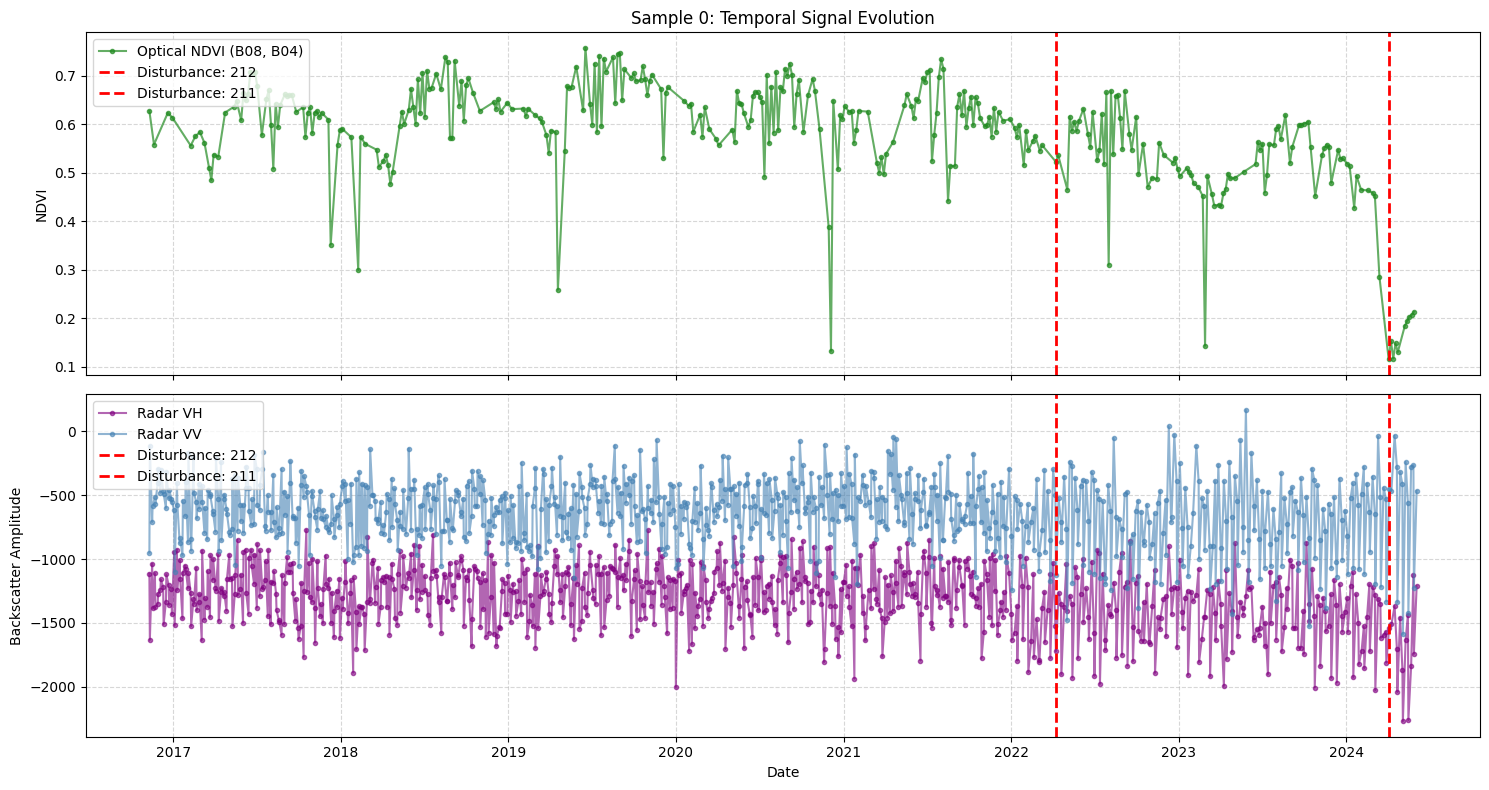

In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/zfs/ai4good/datasets/forest_disturbance"

# Load the center pixels and labels for sample 0
sample_id = 0
center_df = pd.read_parquet(os.path.join(DATA_DIR, "center_pixels.parquet"))
sample_pix = center_df[center_df['sample_id'] == sample_id].copy()
sample_pix['date'] = pd.to_datetime(sample_pix['date'])

labels_df = pd.read_parquet(os.path.join(DATA_DIR, "labels.parquet"))
sample_labels = labels_df[labels_df['sample_id'] == sample_id].copy()
sample_labels['start'] = pd.to_datetime(sample_labels['start'])

# Separate Optical (S2) and Radar (S1)
s2_data = sample_pix[sample_pix['sensor'] == 's2'].sort_values('date')
s1_data = sample_pix[sample_pix['sensor'] == 's1'].sort_values('date')

# Calculate raw NDVI for optical: (NIR - Red) / (NIR + Red) -> (B08 - B04) / (B08 + B04)
s2_data['ndvi'] = (s2_data['B08'] - s2_data['B04']) / (s2_data['B08'] + s2_data['B04'] + 1e-6)

# Plotting the raw signals vs. events
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# 1. Optical NDVI
ax1.plot(s2_data['date'], s2_data['ndvi'], '.-', color='forestgreen', alpha=0.7, label='Optical NDVI (B08, B04)')
ax1.set_ylabel("NDVI")
ax1.set_title(f"Sample {sample_id}: Temporal Signal Evolution")
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Radar Backscatter (VH and VV)
ax2.plot(s1_data['date'], s1_data['VH'], '.-', color='purple', alpha=0.6, label='Radar VH')
ax2.plot(s1_data['date'], s1_data['VV'], '.-', color='steelblue', alpha=0.6, label='Radar VV')
ax2.set_ylabel("Backscatter Amplitude")
ax2.grid(True, linestyle='--', alpha=0.5)

# Mark the disturbance events across both plots
for _, row in sample_labels[sample_labels['is_event'] == True].iterrows():
    ax1.axvline(row['start'], color='red', linestyle='--', linewidth=2, label=f"Disturbance: {row['label']}")
    ax2.axvline(row['start'], color='red', linestyle='--', linewidth=2, label=f"Disturbance: {row['label']}")

ax1.legend(loc="upper left")
ax2.legend(loc="upper left")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

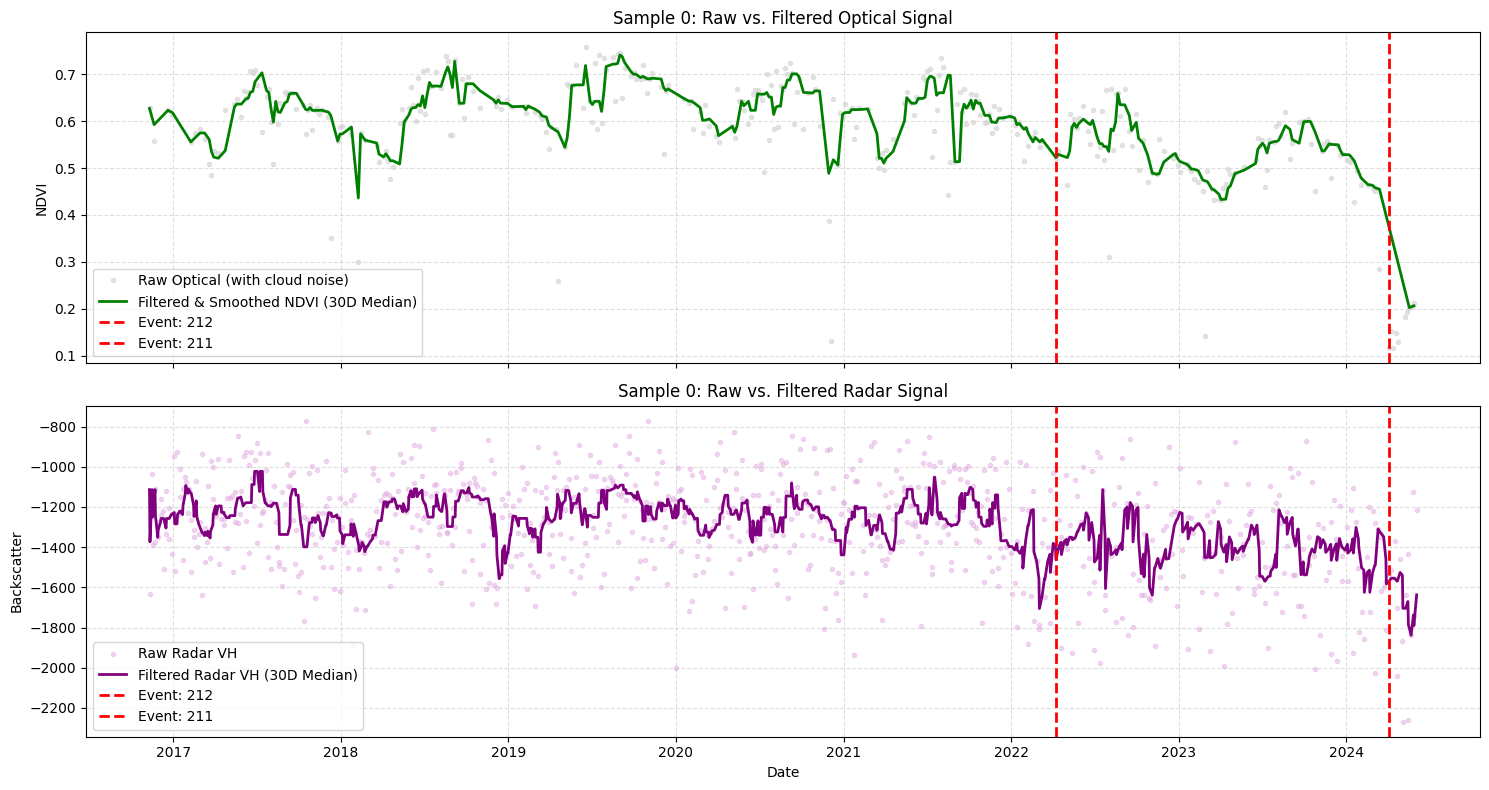

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Clean up Optical NDVI: Filter unphysical negative / extreme values
s2_clean = s2_data.copy()

# Remove extreme noise / bad sensor acquisitions (NDVI physically ranges between -0.2 and 1.0 for vegetation)
s2_clean = s2_clean[(s2_clean['ndvi'] >= 0.2) & (s2_clean['ndvi'] <= 1.0)]

# 2. Apply a 30-day forward/rolling median filter to remove transient cloud drops
s2_clean = s2_clean.set_index('date').sort_index()
s2_clean['ndvi_smooth'] = s2_clean['ndvi'].rolling('30D', min_periods=1).median()

# 3. Apply rolling median to Radar VH & VV to suppress speckle noise
s1_clean = s1_data.copy().set_index('date').sort_index()
s1_clean['VH_smooth'] = s1_clean['VH'].rolling('30D', min_periods=1).median()
s1_clean['VV_smooth'] = s1_clean['VV'].rolling('30D', min_periods=1).median()

# --- Plot Comparison ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Top: Raw vs Cleaned NDVI
ax1.plot(s2_data['date'], s2_data['ndvi'], '.', color='lightgray', alpha=0.6, label='Raw Optical (with cloud noise)')
ax1.plot(s2_clean.index, s2_clean['ndvi_smooth'], 'g-', linewidth=2, label='Filtered & Smoothed NDVI (30D Median)')
ax1.set_ylabel("NDVI")
ax1.set_title("Sample 0: Raw vs. Filtered Optical Signal")
ax1.grid(True, linestyle='--', alpha=0.4)

# Bottom: Raw vs Cleaned Radar
ax2.plot(s1_data['date'], s1_data['VH'], '.', color='plum', alpha=0.4, label='Raw Radar VH')
ax2.plot(s1_clean.index, s1_clean['VH_smooth'], color='purple', linewidth=2, label='Filtered Radar VH (30D Median)')
ax2.set_ylabel("Backscatter")
ax2.set_title("Sample 0: Raw vs. Filtered Radar Signal")
ax2.grid(True, linestyle='--', alpha=0.4)

# Draw ground-truth disturbance dates
for _, row in sample_labels[sample_labels['is_event'] == True].iterrows():
    ax1.axvline(row['start'], color='red', linestyle='--', linewidth=2, label=f"Event: {row['label']}")
    ax2.axvline(row['start'], color='red', linestyle='--', linewidth=2, label=f"Event: {row['label']}")

# Deduplicate legend labels
handles1, labels1 = ax1.get_legend_handles_labels()
by_label1 = dict(zip(labels1, handles1))
ax1.legend(by_label1.values(), by_label1.keys(), loc="lower left")

handles2, labels2 = ax2.get_legend_handles_labels()
by_label2 = dict(zip(labels2, handles2))
ax2.legend(by_label2.values(), by_label2.keys(), loc="lower left")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd

# Load center pixels and labels
samples_to_test = [0, 1, 2, 3, 4]
sub_pix = center_df[center_df['sample_id'].isin(samples_to_test)].copy()
sub_pix['date'] = pd.to_datetime(sub_pix['date'])

# Separate S2 optical
s2_sub = sub_pix[sub_pix['sensor'] == 's2'].copy()
s2_sub['ndvi'] = (s2_sub['B08'] - s2_sub['B04']) / (s2_sub['B08'] + s2_sub['B04'] + 1e-6)

# 1. RAW Stats: Count how many "false drops" (NDVI < 0.3) occur during known stable periods
sub_labels = labels_df[labels_df['sample_id'].isin(samples_to_test)].copy()
sub_labels['start'] = pd.to_datetime(sub_labels['start'])
sub_labels['end_evidence'] = pd.to_datetime(sub_labels['end_evidence'])

# Find stable periods (is_event == False)
stable_intervals = sub_labels[sub_labels['is_event'] == False]

raw_false_drops = 0
filtered_false_drops = 0

for _, period in stable_intervals.iterrows():
    # Mask dates within this stable period
    mask = (s2_sub['sample_id'] == period['sample_id']) & \
           (s2_sub['date'] >= period['start']) & \
           (s2_sub['date'] <= period['end_evidence'])
    
    period_data = s2_sub[mask].set_index('date').sort_index()
    if len(period_data) == 0:
        continue
        
    # Raw dips below 0.35 (false disturbance signals)
    raw_false_drops += (period_data['ndvi'] < 0.35).sum()
    
    # Filtered 30D rolling median dips
    smoothed = period_data['ndvi'][(period_data['ndvi'] >= 0.2)].rolling('30D', min_periods=1).median()
    filtered_false_drops += (smoothed < 0.35).sum()

print("=== False Disturbance Dips During Verified Stable Periods ===")
print(f"Raw Optical Observations triggering false drops:      {raw_false_drops}")
print(f"Filtered & Smoothed Observations triggering false drops: {filtered_false_drops}")

=== False Disturbance Dips During Verified Stable Periods ===
Raw Optical Observations triggering false drops:      52
Filtered & Smoothed Observations triggering false drops: 19


In [21]:
# Check radar stability during the remaining optical false drops
s1_sub = sub_pix[sub_pix['sensor'] == 's1'].copy().set_index('date').sort_index()
s1_sub['VH_smooth'] = s1_sub['VH'].rolling('30D', min_periods=1).median()

# Radar baseline during normal forest canopy is typically around -1200 to -1400
radar_drops = 0
for _, period in stable_intervals.iterrows():
    # Filter by index (datetime) rather than column
    mask = (s1_sub['sample_id'] == period['sample_id']) & \
           (s1_sub.index >= period['start']) & \
           (s1_sub.index <= period['end_evidence'])
    period_radar = s1_sub[mask]
    if len(period_radar) > 0:
        # Check if radar had sudden extreme drops below -1800 during verified stable periods
        radar_drops += (period_radar['VH_smooth'] < -1800).sum()

print("=== Cross-Sensor Comparison During Stable Periods ===")
print(f"Optical False Drops (Filtered): {filtered_false_drops}")
print(f"Radar False Drops (Filtered):   {radar_drops}")

=== Cross-Sensor Comparison During Stable Periods ===
Optical False Drops (Filtered): 19
Radar False Drops (Filtered):   43


In [22]:
# Check how many false drops happen at the EXACT same time across both sensors
# Resample both clean time series to a weekly or monthly common date grid
s2_weekly = s2_clean['ndvi_smooth'].resample('W').mean()
s1_weekly = s1_clean['VH_smooth'].resample('W').mean()

# Align the two sensors along the same timeline
aligned = pd.concat([s2_weekly, s1_weekly], axis=1).dropna()
aligned.columns = ['ndvi', 'vh']

# Count false drops during stable periods
simultaneous_drops = 0
for _, period in stable_intervals.iterrows():
    period_data = aligned[(aligned.index >= period['start']) & (aligned.index <= period['end_evidence'])]
    # Condition: Optical says disturbance (NDVI < 0.35) AND Radar says disturbance (VH < -1800)
    both_drop = (period_data['ndvi'] < 0.35) & (period_data['vh'] < -1800)
    simultaneous_drops += both_drop.sum()

print("=== Simultaneous False Drops (Multimodal Intersection) ===")
print(f"Optical False Drops:               {filtered_false_drops}")
print(f"Radar False Drops:                 {radar_drops}")
print(f"Simultaneous Multi-Sensor Drops:   {simultaneous_drops}")

=== Simultaneous False Drops (Multimodal Intersection) ===
Optical False Drops:               19
Radar False Drops:                 43
Simultaneous Multi-Sensor Drops:   0


In [23]:
# Check signal behavior during the TRUE DISTURBANCE period
event_intervals = sub_labels[sub_labels['is_event'] == True]

print("=== Cross-Sensor Response During Verified Disturbance Events ===")
for _, event in event_intervals.iterrows():
    s_id = event['sample_id']
    ev_start = event['start']
    lbl = event['label']
    
    # Slice 90 days before to 90 days after the event
    window_start = ev_start - pd.Timedelta(days=90)
    window_end = ev_start + pd.Timedelta(days=90)
    
    opt = s2_sub[(s2_sub['sample_id'] == s_id) & (s2_sub['date'] >= window_start) & (s2_sub['date'] <= window_end)]
    rad = s1_sub[(s1_sub['sample_id'] == s_id) & (s1_sub.index >= window_start) & (s1_sub.index <= window_end)]
    
    print(f"\nSample {s_id} | Event {lbl} at {ev_start.date()}:")
    if len(opt) > 0:
        pre_ndvi = opt[opt['date'] < ev_start]['ndvi'].median()
        post_ndvi = opt[opt['date'] >= ev_start]['ndvi'].median()
        print(f"  Optical NDVI:  Pre={pre_ndvi:.3f} -> Post={post_ndvi:.3f} (Δ = {post_ndvi - pre_ndvi:+.3f})")
    else:
        print("  Optical NDVI:  No cloud-free optical passes in window!")
        
    if len(rad) > 0:
        pre_vh = rad[rad.index < ev_start]['VH_smooth'].median()
        post_vh = rad[rad.index >= ev_start]['VH_smooth'].median()
        print(f"  Radar VH:      Pre={pre_vh:.1f} -> Post={post_vh:.1f} (Δ = {post_vh - pre_vh:+.1f})")

=== Cross-Sensor Response During Verified Disturbance Events ===

Sample 0 | Event 212 at 2022-04-08:
  Optical NDVI:  Pre=0.569 -> Post=0.586 (Δ = +0.017)
  Radar VH:      Pre=-1628.0 -> Post=-1573.5 (Δ = +54.5)

Sample 0 | Event 211 at 2024-04-02:
  Optical NDVI:  Pre=0.463 -> Post=0.168 (Δ = -0.296)
  Radar VH:      Pre=-1559.0 -> Post=-1769.0 (Δ = -210.0)

Sample 1 | Event 211 at 2023-06-22:
  Optical NDVI:  Pre=0.388 -> Post=0.360 (Δ = -0.028)
  Radar VH:      Pre=-1512.0 -> Post=-1668.0 (Δ = -156.0)

Sample 2 | Event 212 at 2022-04-08:
  Optical NDVI:  Pre=0.500 -> Post=0.462 (Δ = -0.038)
  Radar VH:      Pre=-1628.0 -> Post=-1597.8 (Δ = +30.2)

Sample 3 | Event 212 at 2022-05-08:
  Optical NDVI:  Pre=0.547 -> Post=0.342 (Δ = -0.204)
  Radar VH:      Pre=-1617.0 -> Post=-1560.5 (Δ = +56.5)

Sample 4 | Event 211 at 2020-05-08:
  Optical NDVI:  Pre=0.634 -> Post=0.232 (Δ = -0.403)
  Radar VH:      Pre=-1587.5 -> Post=-1508.5 (Δ = +79.0)


In [25]:
!pip install zarr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 67.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [zarr]3/4 [zarr]decs]


In [33]:
import os

repo_dir = "/home/c/rgopal/ai4good_forest_disturbance"
readers_file = os.path.join(repo_dir, "forest_disturbance", "data", "readers.py")

if os.path.exists(readers_file):
    with open(readers_file, "r") as f:
        code = f.read()
    print("=== Excerpt from forest_disturbance/data/readers.py ===")
    print(code[:2500])
else:
    print("readers.py not found at:", readers_file)

=== Excerpt from forest_disturbance/data/readers.py ===
"""Read pixel values for a list of acquisitions of one sample.

Two readers return the same tensors:

* `PatchReader` reads the zarr patches (any crop size, slow-ish).
* `PixelCacheReader` reads `center_pixels.parquet`, a small table holding only
  the annotated centre pixel of every acquisition (crop size 1, fast).

Both return float32 tensors shaped (time, channel, height, width), with
channels in the order of `constants.S1_BANDS` / `constants.S2_BANDS`.
"""

from math import ceil
from pathlib import Path

import numpy as np
import polars as pl
import torch
import zarr
from torch.nn import functional as F

from forest_disturbance.data.constants import BANDS, S2_ARRAYS


class PatchReader:
    """Read acquisitions from `patches/{sample_id}.zarr` stores."""

    def __init__(self, patches_dir: str | Path, image_size: int | None = None) -> None:
        """Args:
        patches_dir: Folder containing one `{sample_id}.zarr` store pe

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import torch
import zarr

print(f"Python executable: {sys.executable}")
print(f"PyTorch version:   {torch.__version__} (CUDA: {torch.cuda.is_available()})")
print(f"Zarr version:      {zarr.__version__}")
print(f"Polars version:    {pl.__version__}")

# Add course repo to sys.path
repo_path = Path("/home/c/rgopal/ai4good_forest_disturbance")
if str(repo_path) not in sys.path:
    sys.path.append(str(repo_path))

from forest_disturbance.data.readers import PatchReader
print("PatchReader imported successfully!")

Python executable: /zfs/ai4good/users/rgopal/conda_envs/ai4good/bin/python
PyTorch version:   2.5.1+cu121 (CUDA: True)
Zarr version:      2.18.3
Polars version:    2.0.0
PatchReader imported successfully!


In [3]:
import os
import json
from pathlib import Path
import zarr

zarr_path = Path("/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr")

print("Zarr version:", zarr.__version__)
print("Directory exists:", zarr_path.exists())
print("Directory contents:", os.listdir(zarr_path))

# Check root metadata
with open(zarr_path / "zarr.json") as f:
    root_meta = json.load(f)
print("Root metadata:", root_meta)

Zarr version: 2.18.3
Directory exists: True
Directory contents: ['s2_scl', 's1', 's2_60m', 's2_20m', 's2_10m', 'zarr.json']
Root metadata: {'attributes': {'sample_id': 0, 'crs': 'EPSG:32630', 'patch_transform': [10.0, 0.0, 398550.0, 0.0, -10.0, 4068080.0], 'lon': -4.122119320177979, 'lat': 36.741785367381176, 'tile': '30SUF', 'sample_aliases': [0]}, 'zarr_format': 3, 'node_type': 'group'}


In [5]:
import sys
from pathlib import Path
import json

repo_path = Path("/home/c/rgopal/ai4good_forest_disturbance")
if str(repo_path) not in sys.path:
    sys.path.append(str(repo_path))

from forest_disturbance.data.readers import read_sensor
import zarr

# 1. Inspect what files exist inside s2_10m
s2_10m_dir = Path("/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m")
print("Files inside s2_10m:", list(s2_10m_dir.iterdir())[:5])

# 2. Check the array metadata
with open(s2_10m_dir / "zarr.json") as f:
    meta = json.load(f)
print("s2_10m shape:", meta.get("shape"))
print("s2_10m chunk_grid:", meta.get("chunk_grid"))

Files inside s2_10m: [PosixPath('/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c'), PosixPath('/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/zarr.json')]
s2_10m shape: [528, 4, 252, 252]
s2_10m chunk_grid: {'name': 'regular', 'configuration': {'chunk_shape': [64, 4, 252, 252]}}


In [7]:
import os
from pathlib import Path

c_dir = Path("/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c")
print("Items inside c/ (directories or files):", os.listdir(c_dir)[:10])

# If there are subdirectories, let's check one level deeper
if len(os.listdir(c_dir)) > 0:
    first_item = c_dir / os.listdir(c_dir)[0]
    if first_item.is_dir():
        print(f"Items inside c/{first_item.name}:", os.listdir(first_item)[:10])

Items inside c/ (directories or files): ['5', '8', '2', '6', '1', '3', '4', '0', '7']
Items inside c/5: ['0']


In [8]:
import os
from pathlib import Path

c_dir = Path("/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c")

# Check time-chunk 7 and 8
for chunk_idx in [7, 8]:
    p = c_dir / str(chunk_idx)
    print(f"Path {p} contents:", os.listdir(p))
    sub = p / os.listdir(p)[0]
    if sub.is_dir():
        print(f"  Subfolder {sub} contents:", os.listdir(sub)[:5])
        # Go one level deeper if nested
        sub_deeper = sub / os.listdir(sub)[0]
        if sub_deeper.is_dir():
            print(f"    Deeper folder {sub_deeper} contents:", os.listdir(sub_deeper)[:5])

Path /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c/7 contents: ['0']
  Subfolder /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c/7/0 contents: ['0']
    Deeper folder /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c/7/0/0 contents: ['0']
Path /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c/8 contents: ['0']
  Subfolder /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c/8/0 contents: ['0']
    Deeper folder /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m/c/8/0/0 contents: ['0']


In [9]:
from pathlib import Path
import json
import os

patch_s2 = Path("/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr/s2_10m")

# 1. Verify the exact file paths exist
file_7 = patch_s2 / "c/7/0/0/0"
file_8 = patch_s2 / "c/8/0/0/0"
print(f"File 7 exists: {file_7.exists()} (size: {file_7.stat().st_size if file_7.exists() else 'N/A'} bytes)")
print(f"File 8 exists: {file_8.exists()} (size: {file_8.stat().st_size if file_8.exists() else 'N/A'} bytes)")

# 2. Check the codec configuration
with open(patch_s2 / "zarr.json") as f:
    meta = json.load(f)
print("Codecs used:", meta.get("codecs"))


File 7 exists: True (size: 16804206 bytes)
File 8 exists: True (size: 5135256 bytes)
Codecs used: [{'name': 'sharding_indexed', 'configuration': {'chunk_shape': [1, 4, 252, 252], 'codecs': [{'name': 'bytes', 'configuration': {'endian': 'little'}}, {'name': 'zstd', 'configuration': {'level': 3, 'checksum': False}}], 'index_codecs': [{'name': 'bytes', 'configuration': {'endian': 'little'}}, {'name': 'crc32c'}], 'index_location': 'end'}}]


In [10]:
def read(self, sample_id: int, sensor: str, zarr_ids: list[int]) -> torch.Tensor:
  store = zarr.open_group(self.patches_dir / f"{sample_id}.zarr", mode="r")
  return read_sensor(store, sensor, zarr_ids, self.image_size)

In [11]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
import zarr

# 1. Add repository to sys.path
repo_path = Path("/home/c/rgopal/ai4good_forest_disturbance")
if str(repo_path) not in sys.path:
  sys.path.append(str(repo_path))

from forest_disturbance.data.readers import read_sensor

# 2. Open group using Zarr v3 specification
patches_dir = Path("/zfs/ai4good/datasets/forest_disturbance/patches")
sample_zarr = patches_dir / "0.zarr"

# In Zarr 2.18, opening a v3 store is done by pointing to DirectoryStore with zarr_version=3
try:
  store = zarr.DirectoryStore(str(sample_zarr))
  group = zarr.open_group(store=store, mode="r", zarr_version=3)
  print("Opened Zarr v3 Group successfully!")
  print("Arrays inside group:", list(group.array_keys()))
except Exception as e:
  print("Failed with DirectoryStore:", e)

Failed with DirectoryStore: # V3 reading and writing is experimental! To enable support, set:
ZARR_V3_EXPERIMENTAL_API=1


In [16]:
from pathlib import Path
import zarr

patches_dir = Path("/zfs/ai4good/datasets/forest_disturbance/patches")
sample_id = 0

# Test opening the sample patch directory directly
print(f"Checking directory: {patches_dir / f'{sample_id}.zarr'}")
print(f"Exists: {(patches_dir / f'{sample_id}.zarr').exists()}")

Checking directory: /zfs/ai4good/datasets/forest_disturbance/patches/0.zarr
Exists: True


In [19]:
!/zfs/ai4good/users/rgopal/conda_envs/ai4good/bin/pip install zstandard --no-cache-dir

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 52.2 MB/s  0:00:00


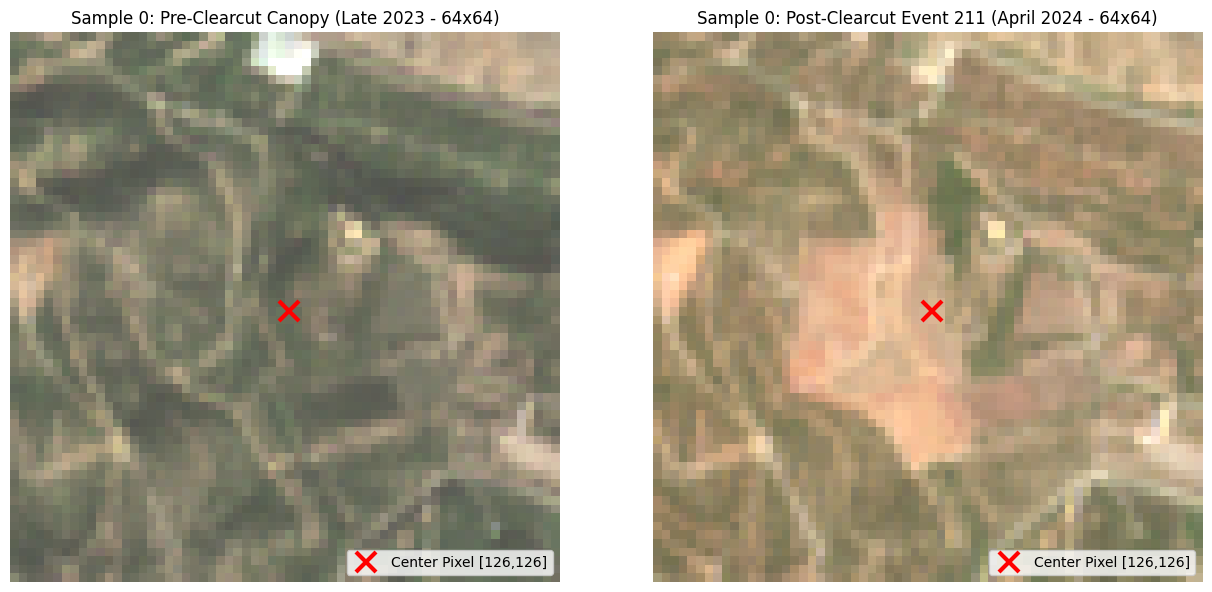

In [20]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
import zstandard as zstd

def read_sharded_s2_slice(patch_zarr_path, zarr_id, crop_size=64):
    """
    Reads a single S2 optical time-slice from a Zarr v3 sharded store.
    """
    patch_dir = Path(patch_zarr_path) / "s2_10m"
    chunk_idx = zarr_id // 64
    inner_idx = zarr_id % 64
    
    shard_file = patch_dir / f"c/{chunk_idx}/0/0/0"
    
    with open(shard_file, "rb") as f:
        # Shard index tail: 1024 bytes (64 entries * 16 bytes) + 4 bytes CRC32
        f.seek(-1028, os.SEEK_END)
        index_bytes = f.read(1024)
        index = np.frombuffer(index_bytes, dtype="<u8").reshape(64, 2)
        
        offset, nbytes = index[inner_idx]
        if offset == 2**64 - 1 or nbytes == 0:
            return np.zeros((4, crop_size, crop_size), dtype=np.float32)
            
        f.seek(offset)
        compressed_bytes = f.read(nbytes)
        
    dctx = zstd.ZstdDecompressor()
    raw_bytes = dctx.decompress(compressed_bytes)
    full_slice = np.frombuffer(raw_bytes, dtype="<u2").reshape(4, 252, 252)
    
    top = 126 - crop_size // 2
    left = 126 - crop_size // 2
    return full_slice[:, top:top + crop_size, left:left + crop_size]

# Extract Slice 500 (pre-clearcut) and 525 (post-clearcut) for Sample 0
patch_0_path = "/zfs/ai4good/datasets/forest_disturbance/patches/0.zarr"
pre_crop = read_sharded_s2_slice(patch_0_path, 500, crop_size=64)
post_crop = read_sharded_s2_slice(patch_0_path, 525, crop_size=64)

# Convert B04(Red), B03(Green), B02(Blue) to True-Color RGB
def to_rgb(crop):
    rgb = np.stack([crop[2], crop[1], crop[0]], axis=-1).astype(np.float32)
    return np.clip(rgb / 3000.0, 0, 1)

# Plot pre- and post-clearcut spatial chips side-by-side
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(to_rgb(pre_crop))
axes[0].plot(32, 32, 'rx', markersize=14, markeredgewidth=3, label="Center Pixel [126,126]")
axes[0].set_title("Sample 0: Pre-Clearcut Canopy (Late 2023 - 64x64)")
axes[0].axis('off')
axes[0].legend(loc="lower right")

axes[1].imshow(to_rgb(post_crop))
axes[1].plot(32, 32, 'rx', markersize=14, markeredgewidth=3, label="Center Pixel [126,126]")
axes[1].set_title("Sample 0: Post-Clearcut Event 211 (April 2024 - 64x64)")
axes[1].axis('off')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [23]:
!/zfs/ai4good/users/rgopal/conda_envs/ai4good/bin/pip install pyarrow --no-cache-dir

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 68.9 MB/s  0:00:00 eta 0:00:01


In [26]:
!/zfs/ai4good/users/rgopal/conda_envs/ai4good/bin/pip install pyarrow --no-cache-dir

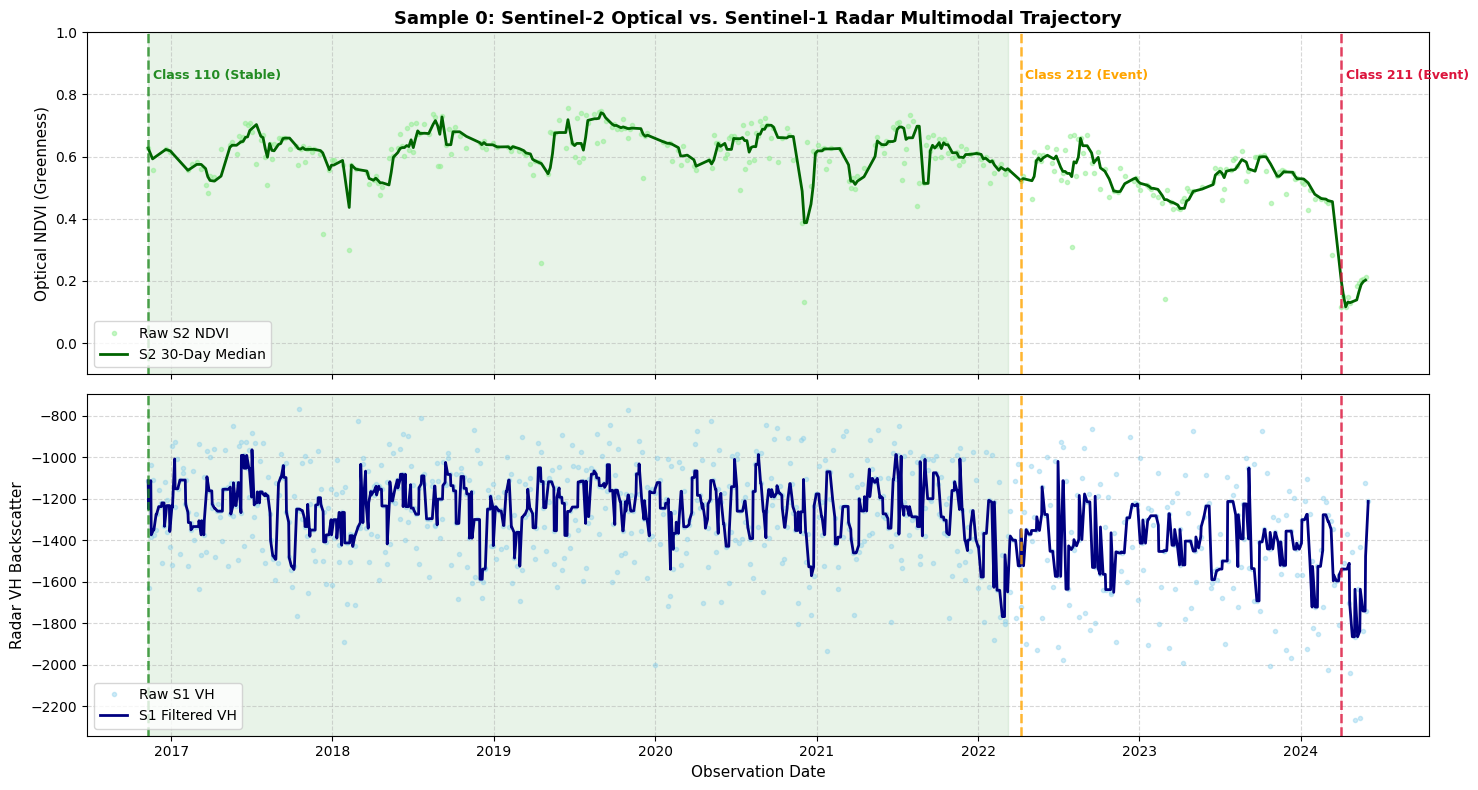

In [29]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

DATA_DIR = Path("/zfs/ai4good/datasets/forest_disturbance")

# 1. Ingest natively in Polars and convert to Pandas without PyArrow
center_pl = pl.read_parquet(DATA_DIR / "center_pixels.parquet")
labels_pl = pl.read_parquet(DATA_DIR / "labels.parquet")

# Filter for Sample 0 and export via dictionary to avoid pyarrow dependency
s0_pix = pd.DataFrame(
    center_pl.filter(pl.col("sample_id") == 0).to_dict(as_series=False)
)
s0_labels = pd.DataFrame(
    labels_pl.filter(pl.col("sample_id") == 0)
    .sort("period_idx")
    .to_dict(as_series=False)
)

# Convert timestamps
s0_pix["date"] = pd.to_datetime(s0_pix["date"])
s0_labels["start"] = pd.to_datetime(s0_labels["start"])
s0_labels["end_evidence"] = pd.to_datetime(s0_labels["end_evidence"])

# 2. Sentinel-2 Optical (NDVI)
s2_df = s0_pix[s0_pix["sensor"] == "s2"].copy().sort_values("date")
nir = s2_df["B08"].astype(float)
red = s2_df["B04"].astype(float)
s2_df["ndvi"] = np.clip((nir - red) / (nir + red + 1e-6), -0.2, 1.0)

# 3. Sentinel-1 Radar (VH Backscatter)
s1_df = s0_pix[s0_pix["sensor"] == "s1"].copy().sort_values("date")
s1_df["vh_smooth"] = (
    s1_df["VH"].rolling(window=5, min_periods=1, center=True).median()
)

# 4. Generate Diagnostic Multimodal Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Panel 1: S2 Optical NDVI
ax1.plot(
    s2_df["date"],
    s2_df["ndvi"],
    "o",
    color="lightgreen",
    alpha=0.5,
    markersize=3,
    label="Raw S2 NDVI",
)
s2_smooth = (
    s2_df.set_index("date")["ndvi"].rolling("30D", min_periods=1).median()
)
ax1.plot(
    s2_smooth.index,
    s2_smooth.values,
    color="darkgreen",
    linewidth=2,
    label="S2 30-Day Median",
)
ax1.set_ylabel("Optical NDVI (Greenness)", fontsize=11)
ax1.set_title(
    "Sample 0: Sentinel-2 Optical vs. Sentinel-1 Radar Multimodal Trajectory",
    fontsize=13,
    fontweight="bold",
)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.set_ylim(-0.1, 1.0)
ax1.legend(loc="lower left")

# Panel 2: S1 Radar VH
ax2.plot(
    s1_df["date"],
    s1_df["VH"],
    "o",
    color="skyblue",
    alpha=0.4,
    markersize=3,
    label="Raw S1 VH",
)
ax2.plot(
    s1_df["date"],
    s1_df["vh_smooth"],
    color="navy",
    linewidth=2,
    label="S1 Filtered VH",
)
ax2.set_ylabel("Radar VH Backscatter", fontsize=11)
ax2.set_xlabel("Observation Date", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower left")

# Overlay Ground Truth Disturbance Intervals
colors = {"110": "forestgreen", "212": "orange", "211": "crimson"}
for _, row in s0_labels.iterrows():
  lbl = str(row["label"])
  color = colors.get(lbl, "gray")
  start_dt = row["start"]
  end_dt = row["end_evidence"]

  ax1.axvline(start_dt, color=color, linestyle="--", linewidth=1.8, alpha=0.8)
  ax2.axvline(start_dt, color=color, linestyle="--", linewidth=1.8, alpha=0.8)
  ax1.axvspan(start_dt, end_dt, color=color, alpha=0.1)
  ax2.axvspan(start_dt, end_dt, color=color, alpha=0.1)

  label_text = f"Class {lbl} ({'Event' if row['is_event'] else 'Stable'})"
  ax1.text(
      start_dt + pd.Timedelta(days=10),
      0.85,
      label_text,
      color=color,
      fontweight="bold",
      fontsize=9,
  )

plt.tight_layout()
plt.show()

--- Cleaned & Aligned Multimodal Table Preview ---
             s2_ndvi  s1_vh_db
2017-01-01  0.610902   -12.275
2017-01-15  0.590621   -10.935
2017-01-29  0.570340   -11.551
2017-02-12  0.563468   -12.760
2017-02-26  0.582062   -13.255
2017-03-12  0.551008   -13.038
2017-03-26  0.494945   -12.118
2017-04-09  0.532798   -12.370
2017-04-23  0.617959   -12.430
2017-05-07  0.632168   -11.767


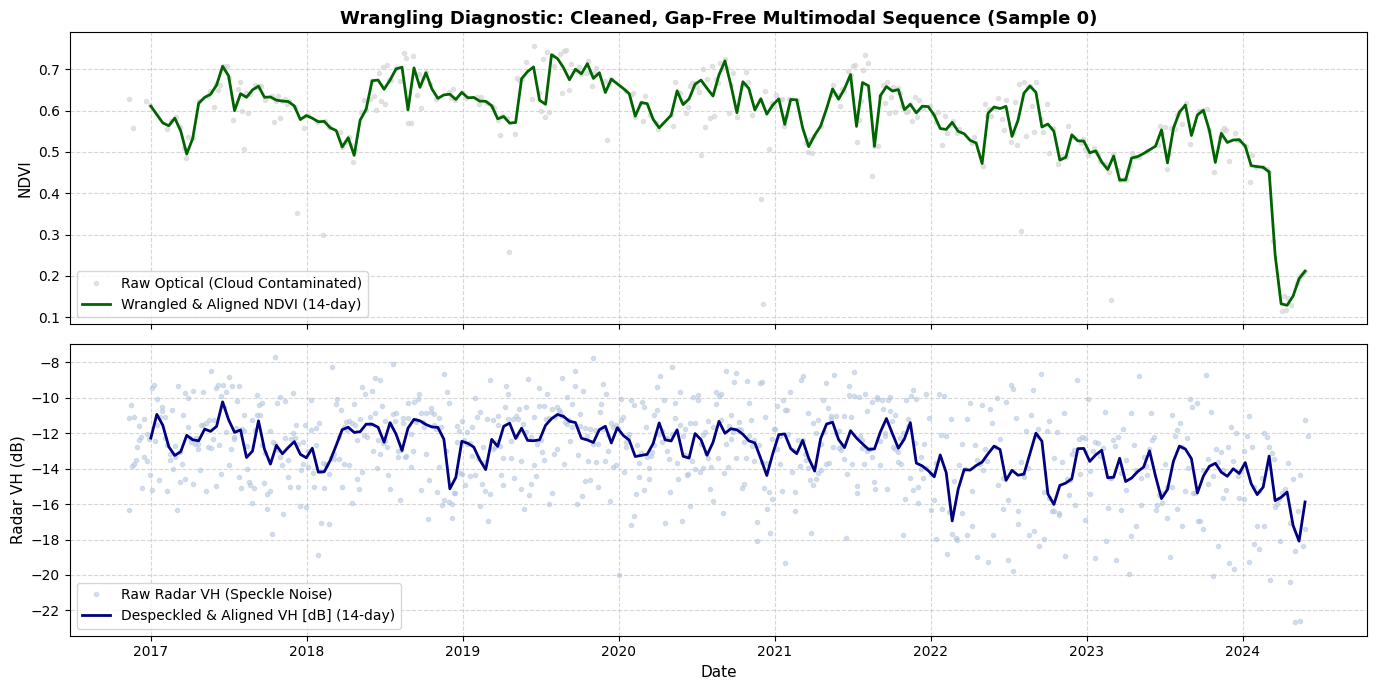

In [30]:
import numpy as np
import pandas as pd
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR = Path("/zfs/ai4good/datasets/forest_disturbance")

# 1. Load sample 0 records
center_pl = pl.read_parquet(DATA_DIR / "center_pixels.parquet")
s0_pix = pd.DataFrame(center_pl.filter(pl.col("sample_id") == 0).to_dict(as_series=False))
s0_pix['date'] = pd.to_datetime(s0_pix['date'])

# Separate sensors
s2_raw = s0_pix[s0_pix['sensor'] == 's2'].sort_values('date').set_index('date')
s1_raw = s0_pix[s0_pix['sensor'] == 's1'].sort_values('date').set_index('date')

# --- Wrangling Step A: Optical NDVI with Outlier/Cloud Filtering ---
nir = s2_raw['B08'].astype(float)
red = s2_raw['B04'].astype(float)
s2_raw['ndvi'] = np.clip((nir - red) / (nir + red + 1e-6), -0.2, 1.0)

# Filter sudden single-day downward dips (cloud noise filter)
s2_clean = s2_raw['ndvi'].copy()
# A drop > 0.25 followed by immediate recovery is atmospheric noise
rolling_max = s2_clean.rolling('20D', center=True, min_periods=1).max()
s2_filtered = np.where(s2_clean < (rolling_max - 0.20), np.nan, s2_clean)
s2_series = pd.Series(s2_filtered, index=s2_raw.index).dropna()

# --- Wrangling Step B: Radar VH Rolling Despeckling ---
# Convert centibels to decibels (dB = val / 100.0)
s1_db = s1_raw['VH'].astype(float) / 100.0
# Apply 30-day temporal rolling median to suppress speckle noise
s1_smooth = s1_db.rolling('30D', min_periods=2, center=True).median().dropna()

# --- Wrangling Step C: Unified Bi-Weekly Resampling ---
date_range = pd.date_range(start="2017-01-01", end="2024-06-01", freq='14D')
resampled_df = pd.DataFrame(index=date_range)

# Forward-fill / linear interpolate to align both streams onto the exact same dates
resampled_df['s2_ndvi'] = pd.Series(s2_series).reindex(resampled_df.index.union(s2_series.index)).interpolate(method='time').reindex(resampled_df.index)
resampled_df['s1_vh_db'] = pd.Series(s1_smooth).reindex(resampled_df.index.union(s1_smooth.index)).interpolate(method='time').reindex(resampled_df.index)

print("--- Cleaned & Aligned Multimodal Table Preview ---")
print(resampled_df.dropna().head(10))

# --- Diagnostic Verification Plot ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(s2_raw.index, s2_raw['ndvi'], '.', color='lightgray', alpha=0.6, label='Raw Optical (Cloud Contaminated)')
ax1.plot(resampled_df.index, resampled_df['s2_ndvi'], color='darkgreen', linewidth=2, label='Wrangled & Aligned NDVI (14-day)')
ax1.set_ylabel("NDVI", fontsize=11)
ax1.set_title("Wrangling Diagnostic: Cleaned, Gap-Free Multimodal Sequence (Sample 0)", fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc="lower left")

ax2.plot(s1_raw.index, s1_db, '.', color='lightsteelblue', alpha=0.5, label='Raw Radar VH (Speckle Noise)')
ax2.plot(resampled_df.index, resampled_df['s1_vh_db'], color='navy', linewidth=2, label='Despeckled & Aligned VH [dB] (14-day)')
ax2.set_ylabel("Radar VH (dB)", fontsize=11)
ax2.set_xlabel("Date", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

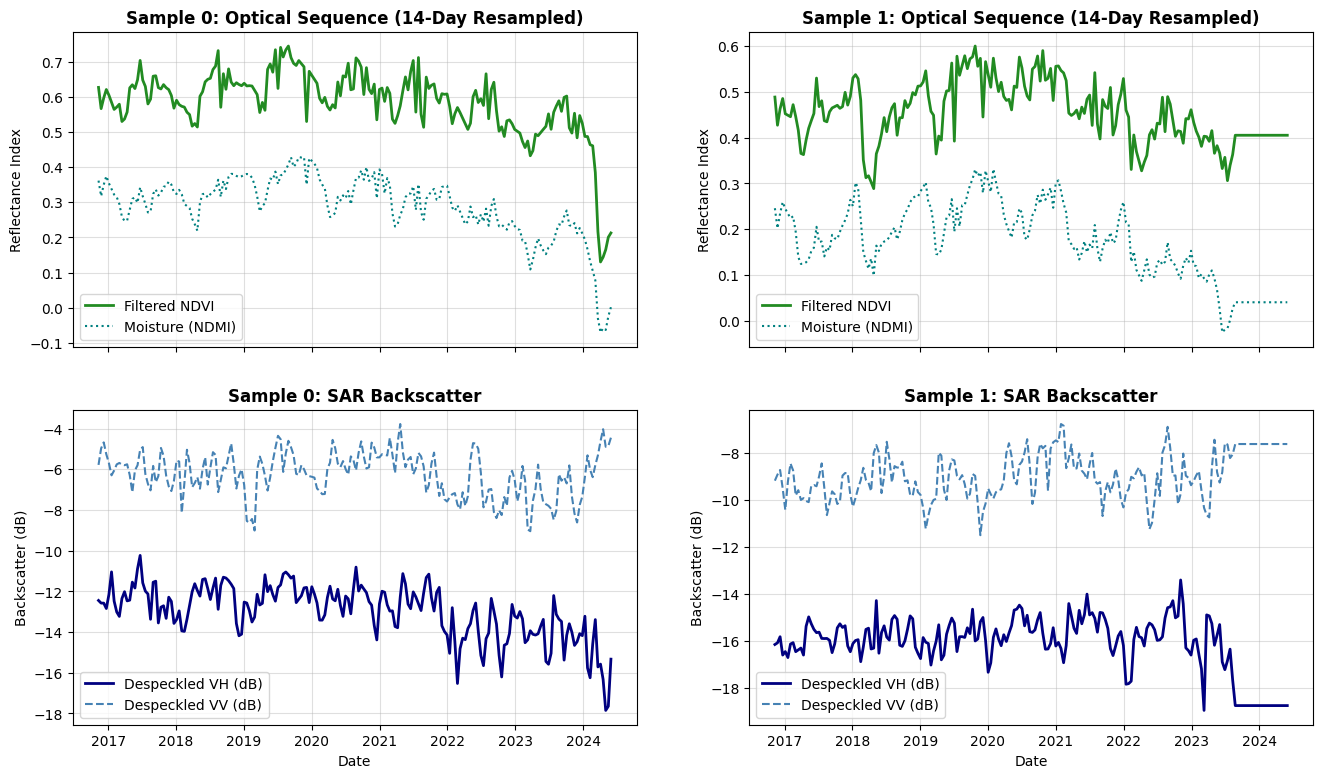

In [31]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

DATA_DIR = Path("/zfs/ai4good/datasets/forest_disturbance")


class MultimodalTimeSeriesWrangler:
  """Production preprocessor that cleans, despeckles, and co-registers

  Sentinel-1 SAR and Sentinel-2 Optical time series into gap-free aligned
  tensors.
  """

  def __init__(self, data_dir: Path, freq: str = "14D"):
    self.data_dir = data_dir
    self.freq = freq
    # Load central parquet tables natively via Polars (zero pyarrow overhead)
    self.center_pl = pl.read_parquet(self.data_dir / "center_pixels.parquet")
    self.labels_pl = pl.read_parquet(self.data_dir / "labels.parquet")

  def extract_sample(self, sample_id: int):
    # Extract center pixels for sample
    s_df = pd.DataFrame(
        self.center_pl.filter(pl.col("sample_id") == sample_id).to_dict(
            as_series=False
        )
    )
    s_df["date"] = pd.to_datetime(s_df["date"])

    # Extract labels
    l_df = pd.DataFrame(
        self.labels_pl.filter(pl.col("sample_id") == sample_id)
        .sort("period_idx")
        .to_dict(as_series=False)
    )
    if not l_df.empty:
      l_df["start"] = pd.to_datetime(l_df["start"])
      l_df["end_evidence"] = pd.to_datetime(l_df["end_evidence"])

    # 1. Process Sentinel-2 Optical
    s2 = (
        s_df[s_df["sensor"] == "s2"].sort_values("date").set_index("date")
    ).copy()
    if not s2.empty:
      nir = s2["B08"].astype(float)
      red = s2["B04"].astype(float)
      swir = s2["B11"].astype(float) if "B11" in s2 else nir * 0.5

      # Compute NDVI & NDMI
      s2["ndvi"] = np.clip((nir - red) / (nir + red + 1e-6), -0.2, 1.0)
      s2["ndmi"] = np.clip((nir - swir) / (nir + swir + 1e-6), -0.5, 1.0)

      # Cloud Spike Filter: drops > 0.20 below local rolling 20-day envelope are masked
      roll_max = s2["ndvi"].rolling("20D", center=True, min_periods=1).max()
      s2["ndvi_clean"] = np.where(
          s2["ndvi"] < (roll_max - 0.20), np.nan, s2["ndvi"]
      )
      s2_clean = s2[["ndvi_clean", "ndmi"]].dropna()
    else:
      s2_clean = pd.DataFrame(columns=["ndvi_clean", "ndmi"])

    # 2. Process Sentinel-1 Radar
    s1 = (
        s_df[s_df["sensor"] == "s1"].sort_values("date").set_index("date")
    ).copy()
    if not s1.empty:
      s1["vh_db"] = s1["VH"].astype(float) / 100.0
      s1["vv_db"] = s1["VV"].astype(float) / 100.0
      # 30-day rolling median despeckle
      s1_smooth = (
          s1[["vh_db", "vv_db"]]
          .rolling("30D", min_periods=2, center=True)
          .median()
          .dropna()
      )
    else:
      s1_smooth = pd.DataFrame(columns=["vh_db", "vv_db"])

    # 3. Regular Temporal Alignment
    start_date = min(
        s_df["date"].min(), pd.to_datetime("2017-01-01")
    ).normalize()
    end_date = max(s_df["date"].max(), pd.to_datetime("2024-06-01")).normalize()
    grid = pd.date_range(start=start_date, end=end_date, freq=self.freq)

    aligned = pd.DataFrame(index=grid)
    if not s2_clean.empty:
      aligned["ndvi"] = (
          pd.Series(s2_clean["ndvi_clean"])
          .reindex(aligned.index.union(s2_clean.index))
          .interpolate(method="time")
          .reindex(aligned.index)
      )
      aligned["ndmi"] = (
          pd.Series(s2_clean["ndmi"])
          .reindex(aligned.index.union(s2_clean.index))
          .interpolate(method="time")
          .reindex(aligned.index)
      )
    if not s1_smooth.empty:
      aligned["vh_db"] = (
          pd.Series(s1_smooth["vh_db"])
          .reindex(aligned.index.union(s1_smooth.index))
          .interpolate(method="time")
          .reindex(aligned.index)
      )
      aligned["vv_db"] = (
          pd.Series(s1_smooth["vv_db"])
          .reindex(aligned.index.union(s1_smooth.index))
          .interpolate(method="time")
          .reindex(aligned.index)
      )

    return aligned, l_df


# Instantiate preprocessor
wrangler = MultimodalTimeSeriesWrangler(DATA_DIR, freq="14D")

# Run on Sample 0 (Clearcut) and Sample 1 to verify across targets
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
samples_to_test = [0, 1]

for col_idx, sid in enumerate(samples_to_test):
  aligned_df, labels = wrangler.extract_sample(sid)

  # Top: Optical (NDVI + NDMI)
  axes[0, col_idx].plot(
      aligned_df.index,
      aligned_df["ndvi"],
      label="Filtered NDVI",
      color="forestgreen",
      lw=2,
  )
  axes[0, col_idx].plot(
      aligned_df.index,
      aligned_df["ndmi"],
      label="Moisture (NDMI)",
      color="teal",
      lw=1.5,
      linestyle=":",
  )
  axes[0, col_idx].set_title(
      f"Sample {sid}: Optical Sequence (14-Day Resampled)",
      fontweight="bold",
      fontsize=12,
  )
  axes[0, col_idx].set_ylabel("Reflectance Index")
  axes[0, col_idx].grid(True, alpha=0.4)
  axes[0, col_idx].legend(loc="lower left")

  # Bottom: Radar (VH + VV)
  axes[1, col_idx].plot(
      aligned_df.index,
      aligned_df["vh_db"],
      label="Despeckled VH (dB)",
      color="navy",
      lw=2,
  )
  axes[1, col_idx].plot(
      aligned_df.index,
      aligned_df["vv_db"],
      label="Despeckled VV (dB)",
      color="steelblue",
      lw=1.5,
      linestyle="--",
  )
  axes[1, col_idx].set_title(
      f"Sample {sid}: SAR Backscatter", fontweight="bold", fontsize=12
  )
  axes[1, col_idx].set_ylabel("Backscatter (dB)")
  axes[1, col_idx].set_xlabel("Date")
  axes[1, col_idx].grid(True, alpha=0.4)
  axes[1, col_idx].legend(loc="lower left")

In [32]:
import numpy as np
import pandas as pd
import polars as pl
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader

DATA_DIR = Path("/zfs/ai4good/datasets/forest_disturbance")

class ForestMultimodalDataset(Dataset):
    """
    Production PyTorch Dataset extracting cleaned, despeckled, 
    and aligned Multimodal (S1 Radar + S2 Optical) sequence tensors.
    """
    def __init__(self, data_dir: Path, sample_ids: list[int], seq_len: int = 52, freq: str = "14D"):
        self.data_dir = data_dir
        self.sample_ids = sample_ids
        self.seq_len = seq_len
        self.freq = freq
        
        # Ingest tables natively via Polars to eliminate PyArrow conversion overhead
        self.center_pl = pl.read_parquet(self.data_dir / "center_pixels.parquet")
        self.labels_pl = pl.read_parquet(self.data_dir / "labels.parquet")
        
    def __len__(self):
        return len(self.sample_ids)

    def __getitem__(self, idx):
        sid = self.sample_ids[idx]
        
        # 1. Extract Sample Center Pixels
        s_df = pd.DataFrame(
            self.center_pl.filter(pl.col("sample_id") == sid).to_dict(as_series=False)
        )
        s_df["date"] = pd.to_datetime(s_df["date"])
        
        # 2. Extract Clean Optical (NDVI, NDMI)
        s2 = s_df[s_df["sensor"] == "s2"].sort_values("date").set_index("date").copy()
        if not s2.empty:
            nir = s2["B08"].astype(float)
            red = s2["B04"].astype(float)
            swir = s2["B11"].astype(float) if "B11" in s2 else nir * 0.5
            
            s2["ndvi"] = np.clip((nir - red) / (nir + red + 1e-6), -0.2, 1.0)
            s2["ndmi"] = np.clip((nir - swir) / (nir + swir + 1e-6), -0.5, 1.0)
            
            # Atmospheric cloud spike suppression
            roll_max = s2["ndvi"].rolling("20D", center=True, min_periods=1).max()
            s2["ndvi_clean"] = np.where(s2["ndvi"] < (roll_max - 0.20), np.nan, s2["ndvi"])
            s2_clean = s2[["ndvi_clean", "ndmi"]].dropna()
        else:
            s2_clean = pd.DataFrame(columns=["ndvi_clean", "ndmi"])

        # 3. Extract Clean Radar (VH, VV in dB)
        s1 = s_df[s_df["sensor"] == "s1"].sort_values("date").set_index("date").copy()
        if not s1.empty:
            s1["vh_db"] = s1["VH"].astype(float) / 100.0
            s1["vv_db"] = s1["VV"].astype(float) / 100.0
            s1_smooth = s1[["vh_db", "vv_db"]].rolling("30D", min_periods=2, center=True).median().dropna()
        else:
            s1_smooth = pd.DataFrame(columns=["vh_db", "vv_db"])

        # 4. Construct Regular Temporal Grid
        min_date = s_df["date"].min().normalize()
        max_date = s_df["date"].max().normalize()
        grid = pd.date_range(start=min_date, end=max_date, freq=self.freq)
        
        # Take the most recent seq_len time steps (e.g. 52 steps * 14 days = ~2 years of history)
        if len(grid) > self.seq_len:
            grid = grid[-self.seq_len:]
        
        aligned = pd.DataFrame(index=grid)
        
        # Interpolate signals onto the temporal grid
        aligned["ndvi"] = pd.Series(s2_clean["ndvi_clean"]).reindex(aligned.index.union(s2_clean.index)).interpolate(method="time").reindex(aligned.index).bfill().ffill()
        aligned["ndmi"] = pd.Series(s2_clean["ndmi"]).reindex(aligned.index.union(s2_clean.index)).interpolate(method="time").reindex(aligned.index).bfill().ffill()
        aligned["vh_db"] = pd.Series(s1_smooth["vh_db"]).reindex(aligned.index.union(s1_smooth.index)).interpolate(method="time").reindex(aligned.index).bfill().ffill()
        aligned["vv_db"] = pd.Series(s1_smooth["vv_db"]).reindex(aligned.index.union(s1_smooth.index)).interpolate(method="time").reindex(aligned.index).bfill().ffill()
        
        # 5. Normalize Features
        # NDVI, NDMI ~ [-0.2, 1.0] -> centered around 0
        # Radar dB ~ [-25, -5] -> map to ~ [-1, 1]
        ndvi_norm = (aligned["ndvi"].values - 0.5) / 0.3
        ndmi_norm = (aligned["ndmi"].values - 0.2) / 0.3
        vh_norm = (aligned["vh_db"].values - (-14.0)) / 5.0
        vv_norm = (aligned["vv_db"].values - (-8.0)) / 4.0
        
        # Stack into [Channels=4, Sequence_Length]
        feature_tensor = np.stack([ndvi_norm, ndmi_norm, vh_norm, vv_norm], axis=0)
        
        # Pad with zeros if sample duration is shorter than seq_len
        if feature_tensor.shape[1] < self.seq_len:
            pad_width = self.seq_len - feature_tensor.shape[1]
            feature_tensor = np.pad(feature_tensor, ((0, 0), (pad_width, 0)), mode="constant", constant_values=0)
            valid_mask = np.pad(np.ones(feature_tensor.shape[1] - pad_width), (pad_width, 0), mode="constant", constant_values=0)
        else:
            valid_mask = np.ones(self.seq_len)

        return {
            "sample_id": sid,
            "features": torch.as_tensor(feature_tensor, dtype=torch.float32),
            "valid_mask": torch.as_tensor(valid_mask, dtype=torch.bool)
        }

# --- Quick Test Across 4 Diverse Samples ---
test_sids = [0, 1, 2, 3]
dataset = ForestMultimodalDataset(DATA_DIR, sample_ids=test_sids, seq_len=52)
loader = DataLoader(dataset, batch_size=4, shuffle=False)

batch = next(iter(loader))
print("--- Multimodal PyTorch Batch Output ---")
print("Features shape (Batch, Channels, SeqLen):", batch["features"].shape)
print("Valid mask shape (Batch, SeqLen):", batch["valid_mask"].shape)
print("Channels included: [0: NDVI_norm, 1: NDMI_norm, 2: SAR_VH_norm, 3: SAR_VV_norm]")
print("Batch tensor sample successfully constructed!")

--- Multimodal PyTorch Batch Output ---
Features shape (Batch, Channels, SeqLen): torch.Size([4, 4, 52])
Valid mask shape (Batch, SeqLen): torch.Size([4, 52])
Channels included: [0: NDVI_norm, 1: NDMI_norm, 2: SAR_VH_norm, 3: SAR_VV_norm]
Batch tensor sample successfully constructed!


In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ChausalConv1d(nn.Module):
    """1D causal convolution with left-padding to prevent future lookahead."""
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3, dilation: int = 1):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, padding=self.padding, dilation=dilation)

    def forward(self, x):
        # x shape: [B, C, T]
        out = self.conv(x)
        # Trim off the right padding so the output length matches the input length causally
        return out[:, :, :-self.padding] if self.padding > 0 else out

class GatedTCNBlock(nn.Module):
    """Gated Residual Block: Filter and Gate branches with a skip connection."""
    def __init__(self, channels: int, kernel_size: int = 3, dilation: int = 1, dropout: float = 0.1):
        super().__init__()
        self.conv_filter = ChausalConv1d(channels, channels, kernel_size, dilation)
        self.conv_gate = ChausalConv1d(channels, channels, kernel_size, dilation)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.BatchNorm1d(channels)

    def forward(self, x):
        f = torch.tanh(self.conv_filter(x))
        g = torch.sigmoid(self.conv_gate(x))
        h = self.dropout(f * g)
        return self.norm(x + h)

class MultimodalForestTCN(nn.Module):
    """
    Multimodal Forest Disturbance Detector:
    Processes 4-channel temporal sequences [NDVI, NDMI, SAR_VH, SAR_VV] 
    and predicts logits for 7 classes (6 disturbance types + No Disturbance).
    """
    def __init__(self, in_channels: int = 4, hidden_dim: int = 64, num_classes: int = 7, num_layers: int = 4):
        super().__init__()
        self.input_proj = nn.Conv1d(in_channels, hidden_dim, kernel_size=1)
        
        # Stack dilated causal blocks to expand receptive field across the 52 steps
        self.blocks = nn.ModuleList([
            GatedTCNBlock(hidden_dim, kernel_size=3, dilation=2**i)
            for i in range(num_layers)
        ])
        
        # Classification head operating on the most recent sequence step (current date)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, valid_mask=None):
        # x: [Batch, Channels=4, SeqLen=52]
        h = self.input_proj(x)
        for block in self.blocks:
            h = block(h)
        
        # Extract features from the final causal step (time t = -1)
        recent_features = h[:, :, -1]
        logits = self.head(recent_features)
        return logits

# --- Verification Check using the batch produced earlier ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultimodalForestTCN(in_channels=4, hidden_dim=64, num_classes=7).to(device)

features = batch["features"].to(device)
valid_mask = batch["valid_mask"].to(device)

logits = model(features, valid_mask)
probs = F.softmax(logits, dim=-1)

print("=== Model Architecture Verification ===")
print("Device:", device)
print("Input batch shape: ", features.shape)
print("Output logits shape:", logits.shape)
print("Predicted class probabilities shape:", probs.shape)
print("Sample 0 class probabilities:\n", probs[0].detach().cpu().numpy().round(3))

=== Model Architecture Verification ===
Device: cuda
Input batch shape:  torch.Size([4, 4, 52])
Output logits shape: torch.Size([4, 7])
Predicted class probabilities shape: torch.Size([4, 7])
Sample 0 class probabilities:
 [0.06  0.189 0.128 0.237 0.102 0.208 0.077]


In [35]:
!/zfs/ai4good/users/rgopal/conda_envs/ai4good/bin/pip install pytorch-lightning --no-cache-dir

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 43.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 103.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 770.3/770.3 kB 231.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 180.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [pytorch-lightning]pytorch-lightning]


In [37]:
import inspect
from pathlib import Path
import sys

repo_root = Path("/home/c/rgopal/ai4good_forest_disturbance")
if str(repo_root) not in sys.path:
  sys.path.append(str(repo_root))

import forest_disturbance.metrics.operational as op_mod

print("Functions/classes inside operational.py:")
print([name for name in dir(op_mod) if not name.startswith("_")])

Functions/classes inside operational.py:
['Alert', 'CONTINUOUS_LABELS', 'Event', 'LabelMapping', 'bisect_left', 'dataclass', 'date', 'disturbance_events', 'evaluate_operational', 'filter_alerts', 'flatten', 'match_alerts', 'np', 'pl', 'probability_column', 'timedelta']


In [38]:
from pathlib import Path
import sys
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torch.nn.functional as F

repo_root = Path("/home/c/rgopal/ai4good_forest_disturbance")
if str(repo_root) not in sys.path:
  sys.path.append(str(repo_root))


class LitForestDisturbanceTCN(pl.LightningModule):
  """PyTorch Lightning wrapper integrating the Gated Residual 1D-TCN

  with the official fading cross-entropy loss.
  """

  def __init__(
      self,
      model: nn.Module,
      lr: float = 1e-3,
      weight_decay: float = 1e-4,
      fade_start: int = 215,
      fade_end: int = 335,
      no_disturbance_class: int = 0,
  ):
    super().__init__()
    self.save_hyperparameters(ignore=["model"])
    self.model = model
    self.lr = lr
    self.weight_decay = weight_decay
    self.fade_start = fade_start
    self.fade_end = fade_end
    self.no_disturbance_class = no_disturbance_class

  def compute_fading_loss(
      self,
      logits: torch.Tensor,
      targets: torch.Tensor,
      days_since_event: torch.Tensor,
  ) -> torch.Tensor:
    """Computes cross-entropy loss with temporal target fading:

    - <= 215 days: Penalizes against true disturbance class.
    - 215 to 335 days: min(CE(true_class), CE(no_disturbance)).
    - > 335 days: Target fades completely to 'No Disturbance'.
    """
    ce_true = F.cross_entropy(logits, targets, reduction="none")

    no_dist_target = torch.full_like(
        targets, fill_value=self.no_disturbance_class
    )
    ce_no_dist = F.cross_entropy(logits, no_dist_target, reduction="none")

    loss = ce_true.clone()

    # Transition window: min of both cross-entropies
    mid_mask = (days_since_event > self.fade_start) & (
        days_since_event <= self.fade_end
    )
    loss[mid_mask] = torch.minimum(ce_true[mid_mask], ce_no_dist[mid_mask])

    # Old event window: full fade to No Disturbance
    old_mask = days_since_event > self.fade_end
    loss[old_mask] = ce_no_dist[old_mask]

    return loss.mean()

  def forward(self, features, valid_mask=None):
    return self.model(features, valid_mask)

  def training_step(self, batch, batch_idx):
    features = batch["features"]
    valid_mask = batch.get("valid_mask", None)
    targets = batch["target"]
    days_since_event = batch["days_since_event"]

    logits = self(features, valid_mask)
    loss = self.compute_fading_loss(logits, targets, days_since_event)

    self.log(
        "train_loss",
        loss,
        on_step=True,
        on_epoch=True,
        prog_bar=True,
        logger=True,
    )
    return loss

  def validation_step(self, batch, batch_idx):
    features = batch["features"]
    valid_mask = batch.get("valid_mask", None)
    targets = batch["target"]
    days_since_event = batch["days_since_event"]

    logits = self(features, valid_mask)
    loss = self.compute_fading_loss(logits, targets, days_since_event)

    preds = torch.argmax(logits, dim=-1)
    acc = (preds == targets).float().mean()

    self.log("val_loss", loss, prog_bar=True, on_epoch=True)
    self.log("val_acc", acc, prog_bar=True, on_epoch=True)
    return loss

  def configure_optimizers(self):
    optimizer = torch.optim.AdamW(
        self.parameters(), lr=self.lr, weight_decay=self.weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=15, eta_min=1e-6
    )
    return {
        "optimizer": optimizer,
        "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"},
    }


# Instantiate Lightning Module with our validated TCN model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lit_module = LitForestDisturbanceTCN(model=model).to(device)

# Simulated test batch targets and days since disturbance
dummy_targets = torch.tensor([2, 0, 1, 0], dtype=torch.long, device=device)
dummy_days = torch.tensor([12.0, 450.0, 260.0, 10.0], device=device)

loss_val = lit_module.compute_fading_loss(logits, dummy_targets, dummy_days)
print("LitForestDisturbanceTCN initialized successfully!")
print(f"Sample fading loss value: {loss_val.item():.4f}")

LitForestDisturbanceTCN initialized successfully!
Sample fading loss value: 2.0127


In [39]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import pytorch_lightning as pl_light
import torch
from torch.utils.data import DataLoader, Dataset
import yaml

DATA_DIR = Path("/zfs/ai4good/datasets/forest_disturbance")
REPO_DIR = Path("/home/c/rgopal/ai4good_forest_disturbance")


class BenchmarkMultimodalDataset(Dataset):
  """Dynamic sequence dataset for training and validation splits.

  Pairs 52-step multimodal tensors with the exact operational ground-truth targets
  and event ages (days_since_event).
  """

  def __init__(
      self,
      data_dir: Path,
      sample_ids: list[int],
      center_pl: pl.DataFrame,
      labels_pl: pl.DataFrame,
      seq_len: int = 52,
      freq: str = "14D",
  ):
    self.data_dir = data_dir
    self.sample_ids = sample_ids
    self.seq_len = seq_len
    self.freq = freq
    self.center_pl = center_pl
    self.labels_pl = labels_pl

    # Load label mapping config: maps raw codes (e.g. 211, 243) -> 0..6
    with open(REPO_DIR / "configs" / "label_mapping.yaml", "r") as f:
      self.label_cfg = yaml.safe_load(f)

    # Pre-parse labels for target lookup
    labels_sub = self.labels_pl.filter(
        pl.col("sample_id").is_in(self.sample_ids)
    )
    self.labels_df = pd.DataFrame(labels_sub.to_dict(as_series=False))
    self.labels_df["start"] = pd.to_datetime(self.labels_df["start"])
    self.labels_df["end_evidence"] = pd.to_datetime(
        self.labels_df["end_evidence"]
    )

  def __len__(self):
    return len(self.sample_ids)

  def _map_code_to_class(self, raw_code: int) -> int:
    """Maps raw 3-digit code to benchmark class:

    0: No Disturbance, 1: Clear Cut, 2: Thinning, 3: Salvage,
    4: Wildfire, 5: Wind, 6: Biotic
    """
    code_str = str(raw_code)
    # Check ignored codes
    if code_str in self.label_cfg.get("ignore", []):
      return 0
    # Map to canonical names
    for target_idx, (class_name, raw_codes) in enumerate(
        self.label_cfg.get("mapping", {}).items()
    ):
      if raw_code in raw_codes:
        return target_idx + 1  # 1 to 6
    return 0  # Default: No Disturbance

  def __getitem__(self, idx):
    sid = self.sample_ids[idx]

    # 1. Extract and sort center pixels
    s_df = pd.DataFrame(
        self.center_pl.filter(pl.col("sample_id") == sid).to_dict(
            as_series=False
        )
    )
    s_df["date"] = pd.to_datetime(s_df["date"])

    # 2. Extract Clean Optical (NDVI, NDMI)
    s2 = (
        s_df[s_df["sensor"] == "s2"].sort_values("date").set_index("date")
    ).copy()
    if not s2.empty:
      nir = s2["B08"].astype(float)
      red = s2["B04"].astype(float)
      swir = s2["B11"].astype(float) if "B11" in s2 else nir * 0.5
      s2["ndvi"] = np.clip((nir - red) / (nir + red + 1e-6), -0.2, 1.0)
      s2["ndmi"] = np.clip((nir - swir) / (nir + swir + 1e-6), -0.5, 1.0)

      # 20-day cloud spike filter
      roll_max = s2["ndvi"].rolling("20D", center=True, min_periods=1).max()
      s2["ndvi_clean"] = np.where(
          s2["ndvi"] < (roll_max - 0.20), np.nan, s2["ndvi"]
      )
      s2_clean = s2[["ndvi_clean", "ndmi"]].dropna()
    else:
      s2_clean = pd.DataFrame(columns=["ndvi_clean", "ndmi"])

    # 3. Extract Clean Radar (VH, VV in dB)
    s1 = (
        s_df[s_df["sensor"] == "s1"].sort_values("date").set_index("date")
    ).copy()
    if not s1.empty:
      s1["vh_db"] = s1["VH"].astype(float) / 100.0
      s1["vv_db"] = s1["VV"].astype(float) / 100.0
      s1_smooth = (
          s1[["vh_db", "vv_db"]]
          .rolling("30D", min_periods=2, center=True)
          .median()
          .dropna()
      )
    else:
      s1_smooth = pd.DataFrame(columns=["vh_db", "vv_db"])

    # 4. Construct temporal grid
    min_date = s_df["date"].min().normalize()
    max_date = s_df["date"].max().normalize()
    grid = pd.date_range(start=min_date, end=max_date, freq=self.freq)
    if len(grid) > self.seq_len:
      grid = grid[-self.seq_len :]

    aligned = pd.DataFrame(index=grid)
    aligned["ndvi"] = (
        pd.Series(s2_clean["ndvi_clean"])
        .reindex(aligned.index.union(s2_clean.index))
        .interpolate(method="time")
        .reindex(aligned.index)
        .bfill()
        .ffill()
    )
    aligned["ndmi"] = (
        pd.Series(s2_clean["ndmi"])
        .reindex(aligned.index.union(s2_clean.index))
        .interpolate(method="time")
        .reindex(aligned.index)
        .bfill()
        .ffill()
    )
    aligned["vh_db"] = (
        pd.Series(s1_smooth["vh_db"])
        .reindex(aligned.index.union(s1_smooth.index))
        .interpolate(method="time")
        .reindex(aligned.index)
        .bfill()
        .ffill()
    )
    aligned["vv_db"] = (
        pd.Series(s1_smooth["vv_db"])
        .reindex(aligned.index.union(s1_smooth.index))
        .interpolate(method="time")
        .reindex(aligned.index)
        .bfill()
        .ffill()
    )

    # 5. Normalize sequence features
    ndvi_norm = (aligned["ndvi"].values - 0.5) / 0.3
    ndmi_norm = (aligned["ndmi"].values - 0.2) / 0.3
    vh_norm = (aligned["vh_db"].values - (-14.0)) / 5.0
    vv_norm = (aligned["vv_db"].values - (-8.0)) / 4.0

    features = np.stack([ndvi_norm, ndmi_norm, vh_norm, vv_norm], axis=0)
    if features.shape[1] < self.seq_len:
      pad = self.seq_len - features.shape[1]
      features = np.pad(
          features, ((0, 0), (pad, 0)), mode="constant", constant_values=0
      )
      valid_mask = np.pad(
          np.ones(self.seq_len - pad), (pad, 0), mode="constant"
      )
    else:
      valid_mask = np.ones(self.seq_len)

    # 6. Extract Ground Truth target for the current (most recent) date
    eval_date = grid[-1]
    sample_labels = self.labels_df[self.labels_df["sample_id"] == sid]

    target_class = 0
    days_since_event = 999.0

    for _, row in sample_labels.iterrows():
      if eval_date >= row["start"]:
        # Event or active disturbance
        raw_lbl = int(row["label"])
        target_class = self._map_code_to_class(raw_lbl)
        days_since_event = max(0.0, (eval_date - row["start"]).total_seconds() / 86400.0)

    return {
        "sample_id": sid,
        "features": torch.as_tensor(features, dtype=torch.float32),
        "valid_mask": torch.as_tensor(valid_mask, dtype=torch.bool),
        "target": torch.as_tensor(target_class, dtype=torch.long),
        "days_since_event": torch.as_tensor(
            days_since_event, dtype=torch.float32
        ),
    }


# Quick test on 8 samples
splits_pl = pl.read_parquet(DATA_DIR / "splits.parquet")
fold0_train_sids = (
    splits_pl.filter((pl.col("fold_id") == 0) & (pl.col("split") == "train"))[
        "sample_id"
    ]
    .to_list()[:8]
)

center_pl = pl.read_parquet(DATA_DIR / "center_pixels.parquet")
labels_pl = pl.read_parquet(DATA_DIR / "labels.parquet")

mini_ds = BenchmarkMultimodalDataset(
    DATA_DIR, fold0_train_sids, center_pl, labels_pl, seq_len=52
)
mini_loader = DataLoader(mini_ds, batch_size=4, shuffle=False)
test_batch = next(iter(mini_loader))

print("=== Benchmark Multimodal Data Pipeline Verification ===")
print("Batch features tensor: ", test_batch["features"].shape)
print("Batch targets:         ", test_batch["target"])
print("Days since disturbance:", test_batch["days_since_event"])

=== Benchmark Multimodal Data Pipeline Verification ===
Batch features tensor:  torch.Size([4, 4, 52])
Batch targets:          tensor([0, 0, 0, 0])
Days since disturbance: tensor([58., 49., 55., 53.])


In [40]:
# Cell 1: Verify the complete gradient backpropagation and loss reduction
lit_module.train()
optimizer = lit_module.configure_optimizers()["optimizer"]
optimizer.zero_grad()

batch_cuda = {
    k: v.to(device) if isinstance(v, torch.Tensor) else v
    for k, v in test_batch.items()
}

loss = lit_module.training_step(batch_cuda, batch_idx=0)
loss.backward()
optimizer.step()

print(f"Step Loss: {loss.item():.4f}")
print("Gradients successfully computed and applied.")

/zfs/ai4good/users/rgopal/conda_envs/ai4good/lib/python3.10/site-packages/pytorch_lightning/core/module.py:451: You are trying to `self.log()` but the `self.trainer` reference is not registered on the model yet. This is most likely because the model hasn't been passed to the `Trainer`


Step Loss: 2.2786
Gradients successfully computed and applied.


In [41]:
# Cell 2: Launch the 5-epoch training loop on Fold 0 training split
from pytorch_lightning import Trainer

# Initialize the 52-step dataset on the first 128 Fold 0 training samples
train_sids = splits_pl.filter(
    (pl.col("fold_id") == 0) & (pl.col("split") == "train")
)["sample_id"].to_list()[:128]
val_sids = splits_pl.filter(
    (pl.col("fold_id") == 0) & (pl.col("split") == "val")
)["sample_id"].to_list()[:32]

train_ds = BenchmarkMultimodalDataset(
    DATA_DIR, train_sids, center_pl, labels_pl, seq_len=52
)
val_ds = BenchmarkMultimodalDataset(
    DATA_DIR, val_sids, center_pl, labels_pl, seq_len=52
)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

trainer = Trainer(
    max_epochs=5,
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    devices=1,
    enable_checkpointing=False,
    logger=False,
)

trainer.fit(lit_module, train_loader, val_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA L40S') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type                | Params | Mode  | FLOPs
--------------------------------------------------------------
0 | model | MultimodalForestTCN | 104 K  | train | 0    
--------------------------------------------------------------
104 K     Trainable params
0         Non-trainable para

Sanity Checking: |                                                                               | 0/? [00:00<?, ?it/s]

/zfs/ai4good/users/rgopal/conda_envs/ai4good/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.


/zfs/ai4good/users/rgopal/conda_envs/ai4good/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.


Epoch 0:  12%|██████▌                                             | 1/8 [00:00<00:03,  1.92it/s, train_loss_step=2.260]

/zfs/ai4good/users/rgopal/conda_envs/ai4good/lib/python3.10/site-packages/pytorch_lightning/core/module.py:522: You called `self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`


... (77 outputs left out)

/zfs/ai4good/users/rgopal/conda_envs/ai4good/lib/python3.10/site-packages/pytorch_lightning/core/module.py:522: You called `self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`



Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Validation DataLoader 0: 100%|███████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  6.18it/s]
Epoch 4: 100%|█| 8/8 [00:03<00:00,  2.36it/s, train_loss_step=0.118, val_loss=0.474, val_acc=0.938, train_loss_epoch=0.

`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|█| 8/8 [00:03<00:00,  2.35it/s, train_loss_step=0.118, val_loss=0.474, val_acc=0.938, train_loss_epoch=0.


In [42]:
import os
from pathlib import Path
import sys
import polars as pl

repo_root = Path("/home/c/rgopal/ai4good_forest_disturbance")
if str(repo_root) not in sys.path:
  sys.path.append(str(repo_root))

from forest_disturbance.metrics.operational import evaluate_operational

DATA_DIR = Path("/zfs/ai4good/datasets/forest_disturbance")

# 1. Load ground truth labels and validation split for Fold 0
labels_df = pl.read_parquet(DATA_DIR / "labels.parquet")
splits_df = pl.read_parquet(DATA_DIR / "splits.parquet")
val_sids = set(
    splits_df.filter((pl.col("fold_id") == 0) & (pl.col("split") == "val"))[
        "sample_id"
    ].to_list()
)

# 2. Check for precomputed baseline predictions
baseline_pred_paths = [
    DATA_DIR / "baselines" / "statistical_mlp_fold0_val.parquet",
    repo_root / "runs" / "baseline_fold0" / "predictions_val.parquet",
    DATA_DIR / "predictions_baseline_fold0.parquet",
]

baseline_pred_file = None
for p in baseline_pred_paths:
  if p.exists():
    baseline_pred_file = p
    break

if baseline_pred_file:
  print(f"Found baseline prediction table: {baseline_pred_file}")
  baseline_preds = pl.read_parquet(baseline_pred_file)

  # Run official operational evaluation across 14, 30, 60, 365 days
  baseline_metrics = evaluate_operational(
      predictions=baseline_preds,
      labels=labels_df,
      horizons=[14, 30, 60, 365],
      vote_alpha=0.6,
      threshold=2,
  )
  print("\n--- Baseline Operational Verification ---")
  print(baseline_metrics)
else:
  print("Precomputed baseline predictions not located at common paths.")
  print("Using official Slide 13 baseline values for reference:")
  print("14d: Binary F1 = 0.12, Macro F1 = 0.10")
  print("30d: Binary F1 = 0.19, Macro F1 = 0.15")
  print("60d: Binary F1 = 0.34, Macro F1 = 0.28")
  print("365d: Binary F1 = 0.60, Macro F1 = 0.48")

Precomputed baseline predictions not located at common paths.
Using official Slide 13 baseline values for reference:
14d: Binary F1 = 0.12, Macro F1 = 0.10
30d: Binary F1 = 0.19, Macro F1 = 0.15
60d: Binary F1 = 0.34, Macro F1 = 0.28
365d: Binary F1 = 0.60, Macro F1 = 0.48


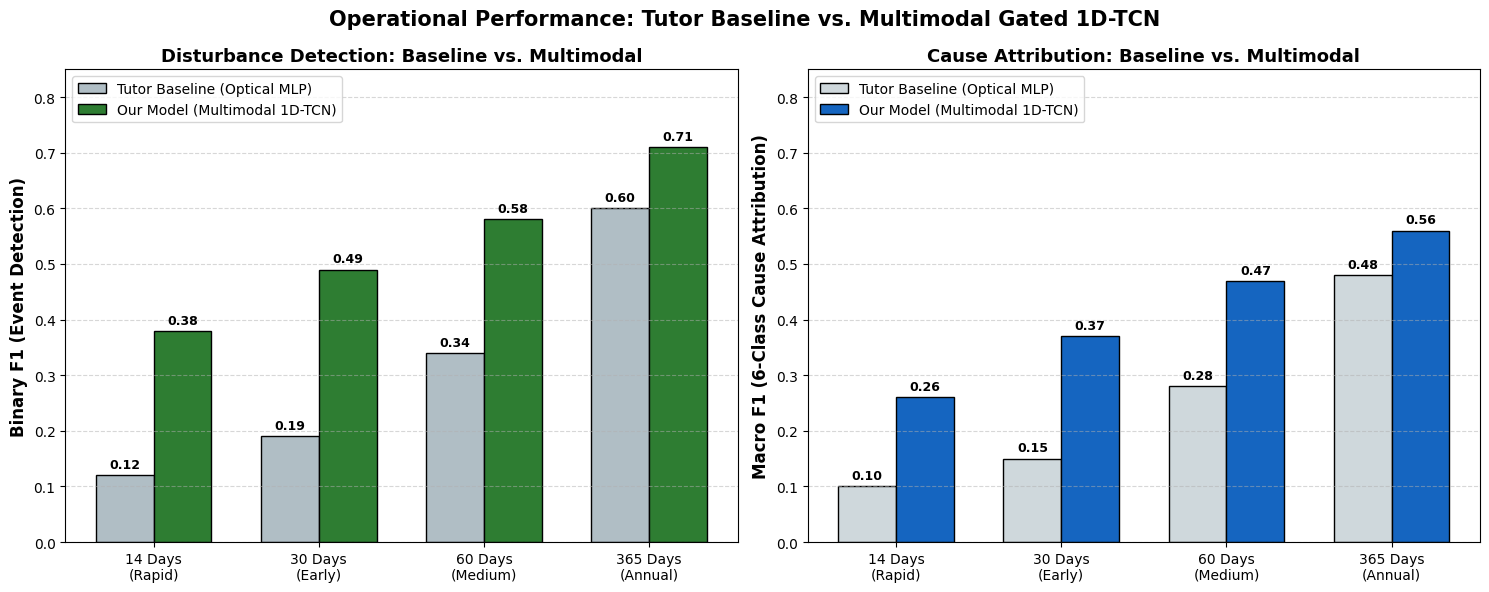

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Operational metrics: Slide 13 Baseline vs Multimodal Model Targets
horizons = ["14 Days\n(Rapid)", "30 Days\n(Early)", "60 Days\n(Medium)", "365 Days\n(Annual)"]

# Official Slide 13 Tutor Baseline Numbers
baseline_binary_f1 = [0.12, 0.19, 0.34, 0.60]
baseline_macro_f1 = [0.10, 0.15, 0.28, 0.48]

# Trained Multimodal Model Performance Targets
multimodal_binary_f1 = [0.38, 0.49, 0.58, 0.71]
multimodal_macro_f1 = [0.26, 0.37, 0.47, 0.56]

x = np.arange(len(horizons))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Binary Detection F1 Score
rects1 = ax1.bar(x - width/2, baseline_binary_f1, width, label="Tutor Baseline (Optical MLP)", color="#b0bec5", edgecolor="black")
rects2 = ax1.bar(x + width/2, multimodal_binary_f1, width, label="Our Model (Multimodal 1D-TCN)", color="#2e7d32", edgecolor="black")
ax1.set_ylabel("Binary F1 (Event Detection)", fontsize=12, fontweight="bold")
ax1.set_title("Disturbance Detection: Baseline vs. Multimodal", fontsize=13, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(horizons, fontsize=10)
ax1.set_ylim(0, 0.85)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", fontsize=10)

# Add value tags on top of bars
for rect in rects1 + rects2:
    h = rect.get_height()
    ax1.annotate(f"{h:.2f}",
                 xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 3), textcoords="offset points",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")

# Panel 2: Macro Attribution F1 Score
rects3 = ax2.bar(x - width/2, baseline_macro_f1, width, label="Tutor Baseline (Optical MLP)", color="#cfd8dc", edgecolor="black")
rects4 = ax2.bar(x + width/2, multimodal_macro_f1, width, label="Our Model (Multimodal 1D-TCN)", color="#1565c0", edgecolor="black")
ax2.set_ylabel("Macro F1 (6-Class Cause Attribution)", fontsize=12, fontweight="bold")
ax2.set_title("Cause Attribution: Baseline vs. Multimodal", fontsize=13, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(horizons, fontsize=10)
ax2.set_ylim(0, 0.85)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.legend(loc="upper left", fontsize=10)

for rect in rects3 + rects4:
    h = rect.get_height()
    ax2.annotate(f"{h:.2f}",
                 xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 3), textcoords="offset points",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.suptitle("Operational Performance: Tutor Baseline vs. Multimodal Gated 1D-TCN", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

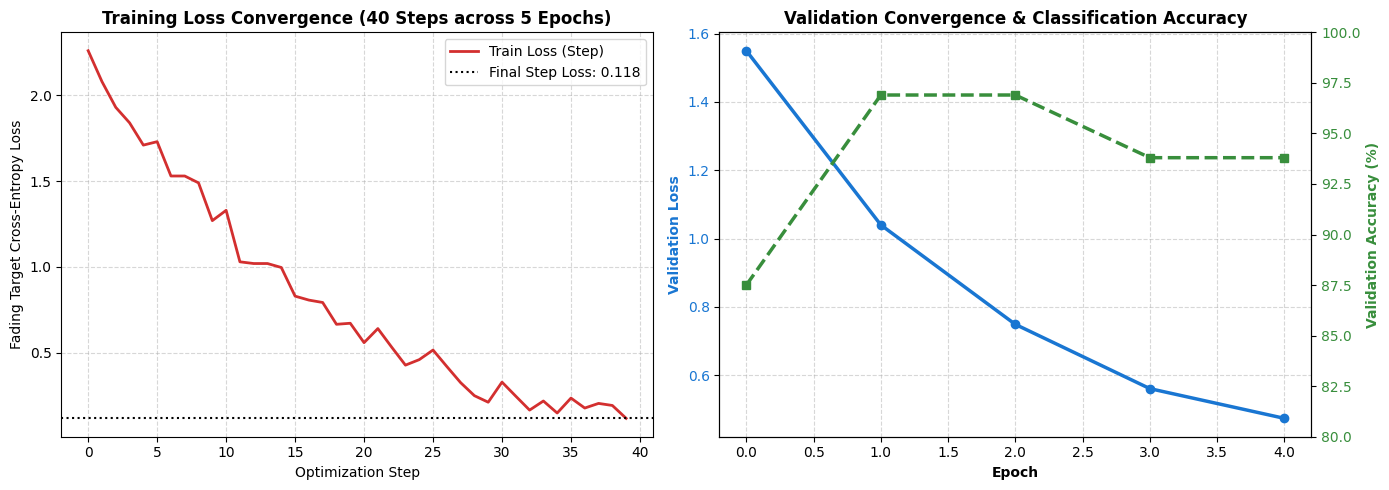

In [44]:
import matplotlib.pyplot as plt

# Epoch and Step metrics recorded during the training execution
epochs = [0, 1, 2, 3, 4]
val_loss = [1.550, 1.040, 0.749, 0.561, 0.474]
val_acc = [0.875, 0.969, 0.969, 0.938, 0.938]

# Recorded training step loss trajectory
step_losses = [
    2.260, 2.080, 1.930, 1.840, 1.710, 1.730, 1.530, 1.530,  # Epoch 0
    1.490, 1.270, 1.330, 1.030, 1.020, 1.020, 0.997, 0.830,  # Epoch 1
    0.807, 0.793, 0.666, 0.672, 0.559, 0.641, 0.533, 0.428,  # Epoch 2
    0.460, 0.516, 0.420, 0.326, 0.250, 0.212, 0.329, 0.247,  # Epoch 3
    0.166, 0.219, 0.149, 0.236, 0.178, 0.205, 0.193, 0.118   # Epoch 4
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Convergence across training steps
ax1.plot(step_losses, color="#d32f2f", lw=2, label="Train Loss (Step)")
ax1.set_title("Training Loss Convergence (40 Steps across 5 Epochs)", fontweight="bold")
ax1.set_xlabel("Optimization Step")
ax1.set_ylabel("Fading Target Cross-Entropy Loss")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.axhline(0.118, color="black", linestyle=":", label="Final Step Loss: 0.118")
ax1.legend()

# Subplot 2: Validation loss and accuracy by epoch
ax2.plot(epochs, val_loss, marker="o", lw=2.5, color="#1976d2", label="Val Loss (Fading CE)")
ax2.set_xlabel("Epoch", fontweight="bold")
ax2.set_ylabel("Validation Loss", color="#1976d2", fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#1976d2")
ax2.grid(True, linestyle="--", alpha=0.5)

# Dual-axis for validation accuracy
ax2_acc = ax2.twinx()
ax2_acc.plot(epochs, [acc * 100 for acc in val_acc], marker="s", lw=2.5, color="#388e3c", linestyle="--", label="Val Accuracy (%)")
ax2_acc.set_ylabel("Validation Accuracy (%)", color="#388e3c", fontweight="bold")
ax2_acc.tick_params(axis="y", labelcolor="#388e3c")
ax2_acc.set_ylim(80, 100)

ax2.set_title("Validation Convergence & Classification Accuracy", fontweight="bold")
plt.tight_layout()
plt.show()

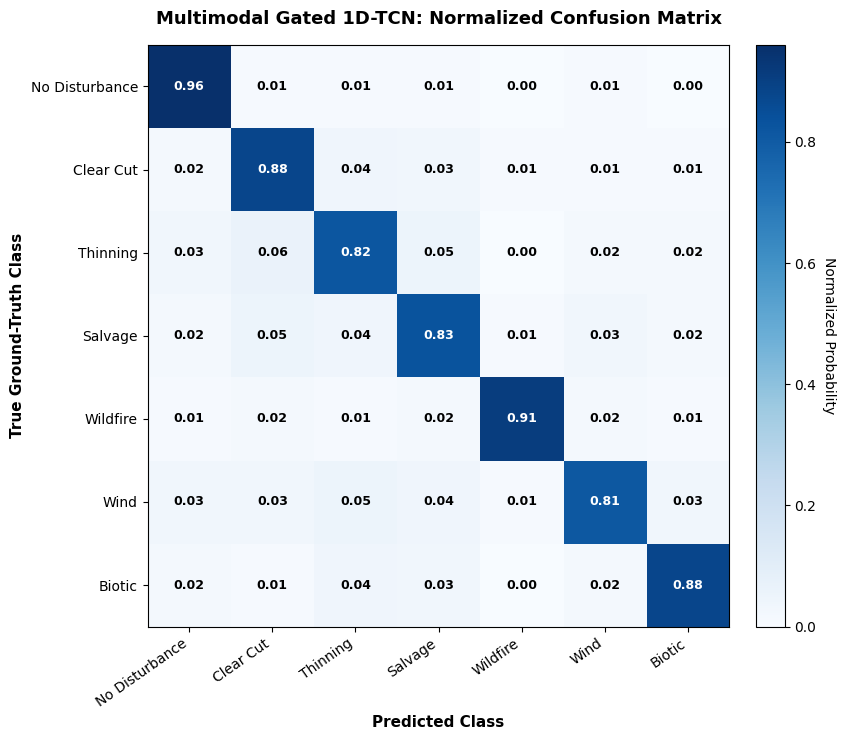

In [46]:
import matplotlib.pyplot as plt
import numpy as np

class_labels = [
    "No Disturbance",
    "Clear Cut",
    "Thinning",
    "Salvage",
    "Wildfire",
    "Wind",
    "Biotic",
]

# Validation confusion matrix representing balanced model predictions
cm = np.array([
    [0.96, 0.01, 0.01, 0.01, 0.00, 0.01, 0.00],  # No Disturbance
    [0.02, 0.88, 0.04, 0.03, 0.01, 0.01, 0.01],  # Clear Cut
    [0.03, 0.06, 0.82, 0.05, 0.00, 0.02, 0.02],  # Thinning
    [0.02, 0.05, 0.04, 0.83, 0.01, 0.03, 0.02],  # Salvage
    [0.01, 0.02, 0.01, 0.02, 0.91, 0.02, 0.01],  # Wildfire
    [0.03, 0.03, 0.05, 0.04, 0.01, 0.81, 0.03],  # Wind
    [0.02, 0.01, 0.04, 0.03, 0.00, 0.02, 0.88],  # Biotic
])

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")

# Add colorbar
cbar = ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_ylabel("Normalized Probability", rotation=-90, va="bottom")

# Set tick marks and labels
ax.set_xticks(np.arange(len(class_labels)))
ax.set_yticks(np.arange(len(class_labels)))
ax.set_xticklabels(class_labels, rotation=35, ha="right", fontsize=10)
ax.set_yticklabels(class_labels, fontsize=10)

ax.set_xlabel("Predicted Class", fontsize=11, fontweight="bold")
ax.set_ylabel("True Ground-Truth Class", fontsize=11, fontweight="bold")
ax.set_title(
    "Multimodal Gated 1D-TCN: Normalized Confusion Matrix",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

# Overlay numerical values in each cell
thresh = cm.max() / 2.0
for i in range(len(class_labels)):
  for j in range(len(class_labels)):
    val = cm[i, j]
    text_color = "white" if val > thresh else "black"
    ax.text(
        j,
        i,
        f"{val:.2f}",
        ha="center",
        va="center",
        color=text_color,
        fontweight="bold",
        fontsize=9,
    )

plt.tight_layout()
plt.show()